# CMPUT 328 — Assignment 3: Object Detection and Instance Segmentation

**Name:** Laurie Gantuangco  
**Student ID:** 1771419 
**AI assistance:** _disclose your usage here (or state none) as required by the report._

You are developing a camera-based autonomous driving system using the BDD100K dataset. Your system must detect cars, pedestrians, and bicycles. Your task is to build a detector and a segmentation model, compare each with pretrained references, and test one change that could improve performance under new conditions. You will then evaluate the performance of your networks against existing pre-trained models.

## Part 0: Setup and Shared Utilities (provided)

A number of utilities are provided for you. Use them throughout parts 1 & 2, and the amount of actual code you write will be fairly minimal. Avoid re-implementing the provided functions yourself.

You should not change any code in this part of the assignment EXCEPT if you are using Google Collab you may wish to change the path to your dataset in google drive in the 2nd code cell below

### 0.1 Get imports and paths
In Colab, select a GPU runtime. Set up your paths to the extracted BDD100K dataset.

In [1]:
%pip install -q pycocotools ultralytics pandas matplotlib tqdm torchvision
import copy
import gc
import json
import math
import os
import multiprocessing
import random
import sys
import time
from collections import Counter, defaultdict
from pathlib import Path
from typing import Any, Iterable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageEnhance
from torch.utils.data import DataLoader, Dataset, TensorDataset
from IPython.display import display
from tqdm.auto import tqdm

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from pycocotools import mask as mask_utils

from matplotlib.colors import to_rgb
from ultralytics import YOLO

# Pre-import sympy.logic to prevent PyTorch singleton_int registration crash on Python 3.14
try:
    import sympy
    import sympy.logic
except ImportError:
    pass

import torchvision.ops
import torchvision.io as tv_io
import torchvision.transforms.functional as TF

# Python 3.14+ defaults to 'forkserver' on Linux, which breaks pickling of notebook classes.
# 'fork' avoids pickling errors and enables multi-worker DataLoader prefetching in Jupyter.
try:
    if hasattr(multiprocessing, "get_all_start_methods") and "fork" in multiprocessing.get_all_start_methods():
        multiprocessing.set_start_method("fork", force=True)
except Exception:
    pass


Note: you may need to restart the kernel to use updated packages.


/home/laurie/CMPUT328/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
try:
    from google.colab import drive
    drive.mount('/content/drive')

    zip_path = "/content/drive/MyDrive/CMPUT328_A3/student_release.zip"
    local_extract_dir = "/content/student_release"
    if not os.path.exists(zip_path) and os.path.exists("/content/student_release.zip"):
        zip_path = "/content/student_release.zip"
    
    # Auto-detect if existing extraction is an older un-letterboxed (1280x720) version
    if os.path.exists(local_extract_dir):
        sample_files = list(Path(local_extract_dir).glob("images/100k/train/*.jpg"))
        if sample_files and tv_io.read_image(str(sample_files[0])).shape[-2:] == (720, 1280):
            print("Detected older un-letterboxed (1280x720) dataset on disk. Removing to re-extract optimized zip...")
            !rm -rf "{local_extract_dir}"

    if os.path.exists(zip_path) and not os.path.exists(local_extract_dir):
        print("Extracting dataset to local runtime... This takes a few seconds.")
        !unzip -q "{zip_path}" -d "/content/"
        print("Extraction complete!")

    DATA_ROOT = Path(local_extract_dir)
    OUTPUT_DIR = Path('/content/drive/MyDrive/CMPUT328_A3/results')
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    # Clean up /dev/shm/train if previously cached to reclaim 4.3 GB of system RAM on Colab
    if os.path.exists('/dev/shm/train'):
        print("Freeing 4.3 GB from /dev/shm/train to prevent out-of-memory crashes...")
        !rm -rf /dev/shm/train


except ImportError:
    # Fallback for running locally on your own machine
    print('Not running in Google Colab')
    DATA_ROOT = Path('./student_release')
    OUTPUT_DIR = Path('./results')

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ("car", "pedestrian", "bicycle")
CLASS_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}
BDD_TO_CLASS = {"car": 0, "pedestrian": 1, "person": 1, "rider": 1, "bicycle": 2, "bike": 2}
IMAGE_WIDTH, IMAGE_HEIGHT = 640, 384
MEAN = torch.tensor((0.485, 0.456, 0.406), dtype=torch.float32)[:, None, None]
STD = torch.tensor((0.229, 0.224, 0.225), dtype=torch.float32)[:, None, None]


Not running in Google Colab


### 0.2 Core Setup & Reproducibility

In [3]:
def set_seeds(seed: int = 328) -> None:
    """Sets random seeds for Python, NumPy, and PyTorch to ensure reproducible runs."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    # Enable cuDNN auto-tuning for fast convolutions on fixed image resolutions
    torch.backends.cudnn.benchmark = True
    torch.backends.cudnn.deterministic = False
    try:
        torch.set_float32_matmul_precision('high')
    except Exception:
        pass

def denormalize_image(image: torch.Tensor) -> torch.Tensor:
    """Reverts ImageNet normalization for visualization."""
    return (image.detach().cpu() * STD + MEAN).clamp(0, 1)

def collate_batch(batch):
    """Collates a list of dataset items into a batched image tensor and a list of target dicts."""
    images, targets = zip(*batch)
    return torch.stack(images), list(targets)

### 0.3 BDD100K Data and Parsing Utilities

In [4]:
def _normalize_timeofday(value: Any) -> str:
    """Standardizes time-of-day strings from the BDD100k metadata."""
    value = str(value or "unknown").strip().lower()
    if value in {"day", "daytime"}:
        return "daytime"
    if value in {"night", "nighttime"}:
        return "nighttime"
    return "other"

def _record_timeofday(record: dict[str, Any]) -> str:
    """Extracts the time of day from an image annotation record."""
    return _normalize_timeofday((record.get("attributes") or {}).get("timeofday"))

_RECORDS_CACHE = {}
_MASK_BYTE_CACHE = {}

def _read_records(path: Path) -> list[dict[str, Any]]:
    """Loads the BDD100K JSON annotation file with in-memory caching to prevent duplicating large dicts."""
    p_str = str(Path(path).resolve())
    if p_str not in _RECORDS_CACHE:
        with Path(path).open("r", encoding="utf8") as f:
            records = json.load(f)
        if isinstance(records, dict):
            records = records.get("data", records.get("images", []))
        _RECORDS_CACHE[p_str] = records
    return _RECORDS_CACHE[p_str]

def _boxes_and_labels(record: dict[str, Any]) -> tuple[list[list[float]], list[int]]:
    """Extracts bounding boxes and translates BDD100K classes to our subset (car, pedestrian, bicycle)."""
    boxes, labels = [], []
    for item in record.get("labels", []) or []:
        class_id = BDD_TO_CLASS.get(str(item.get("category", "")).strip().lower())
        box = item.get("box2d")
        if class_id is None or not isinstance(box, dict):
            continue
        try:
            coords = [float(box[k]) for k in ("x1", "y1", "x2", "y2")]
            # Validate coordinates form a proper box
            if np.isfinite(coords).all() and coords[2] > coords[0] and coords[3] > coords[1]:
                boxes.append(coords)
                labels.append(class_id)
        except (KeyError, TypeError, ValueError):
            continue
    return boxes, labels

def _mask_instances(mask_path: Path) -> tuple[list[np.ndarray], list[int]]:
    """Decodes BDD100K bitmask PNGs into separate binary masks per instance with RAM byte caching."""
    p_str = str(mask_path)
    raw = _MASK_BYTE_CACHE.get(p_str)
    if raw is None:
        with open(mask_path, "rb") as f:
            raw = bytearray(f.read())
        if len(_MASK_BYTE_CACHE) < 5000:
            _MASK_BYTE_CACHE[p_str] = raw
    buf = torch.frombuffer(raw, dtype=torch.uint8)
    rgba = tv_io.decode_image(buf, mode=tv_io.ImageReadMode.RGB_ALPHA).permute(1, 2, 0).numpy()
    cat = rgba[..., 0].astype(np.int32)
    inst = (rgba[..., 2].astype(np.int32) << 8) | rgba[..., 3].astype(np.int32)
    packed = (cat << 24) | inst
    unique_vals = np.unique(packed)
    masks, labels = [], []
    for val in unique_vals:
        c = int(val >> 24)
        i = int(val & 0xFFFFFF)
        if c == 0 or i == 0:
            continue
        binary = (packed == val)
        if binary.any():
            masks.append(binary)
            labels.append(c - 1)
    return masks, labels

def _box_from_mask(mask: torch.Tensor) -> torch.Tensor:
    """Generates a tight bounding box around a binary mask."""
    ys, xs = torch.where(mask)
    if xs.numel() == 0:
        return torch.zeros(4, dtype=torch.float32)
    return torch.tensor((xs.min().item(), ys.min().item(), xs.max().item() + 1, ys.max().item() + 1), dtype=torch.float32)


In [5]:
_IMAGE_BYTE_CACHE = {}
MAX_IMAGE_CACHE_ITEMS = 8000

class BDD100KDataset(Dataset):
    """Loads images, bounding boxes, and masks, applying letterbox padding and augmentations."""
    def __init__(self, annotation_json, image_root, mask_root=None, image_size=(IMAGE_WIDTH, IMAGE_HEIGHT), timeofday=None, horizontal_flip=False, lighting_augmentation=False, normalize=True):
        self.annotation_json = Path(annotation_json)
        self.image_root = Path(image_root)
        self.mask_root = Path(mask_root) if (mask_root and Path(mask_root).is_dir()) else None
        
        self.image_width, self.image_height = image_size
        self.horizontal_flip = horizontal_flip
        self.lighting_augmentation = lighting_augmentation
        self.normalize = normalize
        
        self.records = _read_records(self.annotation_json)
        self.active_indices = list(range(len(self.records)))
        self._image_paths = [self.image_root / str(r.get("name") or r.get("filename")) for r in self.records]
        self._coco_cache = None
        
        # Filter dataset by time of day if requested
        if timeofday:
            key = _normalize_timeofday(timeofday)
            self.active_indices = [i for i, row in enumerate(self.records) if _record_timeofday(row) == key]

    def view(self, *, timeofday=None, indices=None):
        """Creates a shallow copy of the dataset filtered by criteria, useful for creating splits."""
        result = copy.copy(self)
        result._coco_cache = None
        if indices is not None:
            result.active_indices = list(indices)
        elif timeofday is not None:
            key = _normalize_timeofday(timeofday)
            result.active_indices = [i for i in self.active_indices if _record_timeofday(self.records[i]) == key]
        return result

    def __len__(self):
        return len(self.active_indices)

    def _image_path(self, source_index: int) -> Path:
        p = self._image_paths[source_index]
        return p if p.is_file() else list(self.image_root.rglob(p.name))[0]

    def _mask_path(self, source_index: int, image_path: Path) -> Path:
        path = self.mask_root / f"{image_path.stem}.png"
        if path.is_file():
            return path
        matches = list(self.mask_root.rglob(f"{image_path.stem}.png"))
        if matches:
            return matches[0]
        raise FileNotFoundError(f"Mask for {image_path.name} not found under {self.mask_root}")

    def class_counts(self) -> tuple[Counter, int]:
        """Returns the distribution of object classes in the current active dataset view."""
        counts = Counter()
        for idx in self.active_indices:
            _, labels = _boxes_and_labels(self.records[idx])
            counts.update(CLASS_NAMES[l] for l in labels)
        return counts, len(self.active_indices)

    def __getitem__(self, index: int):
        source_index = self.active_indices[index]
        row = self.records[source_index]
        image_path = self._image_path(source_index)
        
        # Bounded raw-byte RAM caching: avoids Colab disk I/O bottlenecks while keeping memory usage under ~550 MB
        p_str = str(image_path)
        raw_bytes = _IMAGE_BYTE_CACHE.get(p_str)
        if raw_bytes is None:
            with open(image_path, "rb") as f:
                raw_bytes = bytearray(f.read())
            if len(_IMAGE_BYTE_CACHE) < MAX_IMAGE_CACHE_ITEMS:
                _IMAGE_BYTE_CACHE[p_str] = raw_bytes
        image = tv_io.decode_image(torch.frombuffer(raw_bytes, dtype=torch.uint8), mode=tv_io.ImageReadMode.RGB)
        
        _, h, w = image.shape
        boxes, labels = _boxes_and_labels(row)

        original_masks, mask_labels = [], []
        if self.mask_root:
            original_masks, mask_labels = _mask_instances(self._mask_path(source_index, image_path))

        # Check if pre-letterboxed or unscaled raw image
        if (w, h) == (self.image_width, self.image_height):
            original_width, original_height = (1280, 720)
            scale = 0.5
            rw, rh = 640, 360
            pad_x, pad_y = 0.0, 12.0
        else:
            original_width, original_height = w, h
            scale = min(self.image_width / original_width, self.image_height / original_height)
            rw, rh = max(1, round(original_width * scale)), max(1, round(original_height * scale))
            pad_x, pad_y = float((self.image_width - rw) // 2), float((self.image_height - rh) // 2)
            image = TF.resize(image, [rh, rw], interpolation=TF.InterpolationMode.BILINEAR, antialias=False)
            image = F.pad(image, (int(pad_x), self.image_width - rw - int(pad_x), int(pad_y), self.image_height - rh - int(pad_y)), value=114)

        # 1. Apply Image Augmentations directly on tensor
        if self.lighting_augmentation:
            image = TF.adjust_brightness(image, random.uniform(0.55, 1.45))
            image = TF.adjust_contrast(image, random.uniform(0.65, 1.35))

        if self.horizontal_flip and random.random() < 0.5:
            image = image.flip(-1)
            boxes = [[original_width - x2, y1, original_width - x1, y2] for x1, y1, x2, y2 in boxes]
            original_masks = [np.fliplr(mask).copy() for mask in original_masks]

        # Compact uint8 tensor saves 75% multiprocessing IPC overhead; normalized on GPU during training
        if self.normalize:
            image_tensor = image.to(torch.float32).div_(255.0).sub_(MEAN).div_(STD)
        else:
            image_tensor = image  # uint8 tensor [3, H, W]

        # 3. Scale Bounding Boxes
        target = {
            "boxes": torch.tensor([[x1 * scale + pad_x, y1 * scale + pad_y, x2 * scale + pad_x, y2 * scale + pad_y] for x1, y1, x2, y2 in boxes], dtype=torch.float32).reshape(-1, 4),
            "labels": torch.tensor(labels, dtype=torch.long),
            "orig_boxes": torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4),
            "image_id": int(source_index),
            "original_size": (original_height, original_width),
            "scale": float(scale),
            "pad": (float(pad_x), float(pad_y)),
            "timeofday": _record_timeofday(row), 
            "image_path": str(image_path), 
            "file_name": image_path.name,
        }
        
        # 4. Scale Instance Masks
        if self.mask_root:
            transformed_masks, transformed_mask_boxes = [], []
            for raw_mask in original_masks:
                if raw_mask.shape == (self.image_height, self.image_width):
                    mask_tensor = torch.from_numpy(raw_mask)
                else:
                    m_t = torch.from_numpy(raw_mask.astype(np.uint8))
                    m_resized = TF.resize(m_t.unsqueeze(0), [rh, rw], interpolation=TF.InterpolationMode.NEAREST)[0]
                    mask_tensor = F.pad(m_resized, (int(pad_x), self.image_width - rw - int(pad_x), int(pad_y), self.image_height - rh - int(pad_y)), value=0) > 0
                transformed_masks.append(mask_tensor)
                transformed_mask_boxes.append(_box_from_mask(mask_tensor))
                
            target.update({
                "instance_masks": transformed_masks, 
                "instance_labels": torch.tensor(mask_labels, dtype=torch.long),
                "instance_boxes": torch.stack(transformed_mask_boxes) if transformed_mask_boxes else torch.zeros((0, 4)),
            })
            
        return image_tensor, target

def sample_view(dataset, max_images, seed=328):
    """Subsamples a dataset to speed up training iterations when in FAST_MODE."""
    if max_images <= 0 or len(dataset) <= max_images:
        return dataset.view(indices=dataset.active_indices)
    return dataset.view(indices=[dataset.active_indices[i] for i in sorted(random.Random(seed).sample(range(len(dataset)), max_images))])


### 0.4 Segmentation & Cropping Utilities

In [6]:
def build_instance_crops(image, target, crop_size=128, minimum_box_iou=0.10):
    """Extracts uniform square crops of objects and their masks for training the segmentation model."""
    gt_boxes, gt_labels = target["boxes"], target["labels"]
    mask_boxes, mask_labels = target["instance_boxes"], target["instance_labels"]
    
    if len(gt_boxes) == 0 or len(mask_boxes) == 0: 
        return {"crops": torch.zeros((0, 3, crop_size, crop_size)), "masks": torch.zeros((0, 1, crop_size, crop_size)), "labels": torch.zeros((0,), dtype=torch.long)}
    
    # 1. Match masks to ground truth boxes using IoU
    pairs = []
    for gi, (gbox, glabel) in enumerate(zip(gt_boxes.cpu().numpy(), gt_labels.tolist())):
        for mi, (mbox, mlabel) in enumerate(zip(mask_boxes.cpu().numpy(), mask_labels.tolist())):
            if glabel == mlabel:
                left, right = np.maximum(gbox[:2], mbox[:2]), np.minimum(gbox[2:], mbox[2:])
                inter = np.maximum(right - left, 0).prod()
                iou = inter / max(1e-9, (gbox[2]-gbox[0])*(gbox[3]-gbox[1]) + (mbox[2]-mbox[0])*(mbox[3]-mbox[1]) - inter)
                if iou >= minimum_box_iou: 
                    pairs.append((iou, gi, mi))
    
    # Greedy matching from highest IoU to lowest
    pairs.sort(reverse=True)
    used_gt, used_mask, selected = set(), set(), []
    for _, gi, mi in pairs:
        if gi not in used_gt and mi not in used_mask:
            selected.append((gi, mi))
            used_gt.add(gi)
            used_mask.add(mi)
            
    # 2. Extract and resize the crops
    crops, mask_crops, labels = [], [], []
    h, w = image.shape[-2:]
    for gi, mi in selected:
        x1, y1, x2, y2 = gt_boxes[gi].round().long().tolist()
        x1, x2 = max(0, min(x1, w-1)), max(1, min(x2, w))
        y1, y2 = max(0, min(y1, h-1)), max(1, min(y2, h))
        
        if x2 <= x1 or y2 <= y1: 
            continue
            
        crops.append(F.interpolate(image[:, y1:y2, x1:x2][None], size=(crop_size, crop_size), mode="bilinear", align_corners=False)[0])
        mask_crops.append(F.interpolate(target["instance_masks"][mi][None, None, y1:y2, x1:x2].float(), size=(crop_size, crop_size), mode="nearest")[0])
        labels.append(int(gt_labels[gi]))
        
    return {
        "crops": torch.stack(crops) if crops else torch.zeros((0, 3, crop_size, crop_size)), 
        "masks": torch.stack(mask_crops) if mask_crops else torch.zeros((0, 1, crop_size, crop_size)), 
        "labels": torch.tensor(labels, dtype=torch.long)
    }

def paste_crop_masks(mask_probs, boxes, image_size, threshold=0.50):
    """Takes mask predictions generated from crops and pastes them back onto the full image canvas."""
    h, w = image_size
    if mask_probs.ndim == 4: 
        mask_probs = mask_probs[:, 0]
        
    output = torch.zeros((len(boxes), h, w), dtype=torch.bool, device=mask_probs.device)
    for i, (box, prob) in enumerate(zip(boxes, mask_probs)):
        x1, y1, x2, y2 = box.round().long().tolist()
        x1, x2 = max(0, min(x1, w-1)), max(1, min(x2, w))
        y1, y2 = max(0, min(y1, h-1)), max(1, min(y2, h))
        
        if x2 <= x1 or y2 <= y1: 
            continue
            
        output[i, y1:y2, x1:x2] = F.interpolate(prob[None, None], size=(y2-y1, x2-x1), mode="bilinear", align_corners=False)[0, 0] >= threshold
        
    return output

### 0.5 Inference & Evaluation Helpers

In [7]:
def inverse_letterbox_boxes(boxes, target):
    """Reverts letterbox scaling so predictions align with the original unpadded image."""
    if boxes.numel() == 0: 
        return boxes.reshape(-1, 4)
        
    scale = float(target["scale"])
    pad_x, pad_y = target["pad"]
    h, w = target["original_size"]
    
    result = boxes.clone()
    result[:, [0, 2]] = ((result[:, [0, 2]] - pad_x) / scale).clamp(0, w)
    result[:, [1, 3]] = ((result[:, [1, 3]] - pad_y) / scale).clamp(0, h)
    return result

def collect_predictions(model, dataset, device, batch_size=32, workers=0, desc="Evaluating"):
    """Runs a model over a dataset and formats the predictions for the COCO evaluator."""
    loader = DataLoader(
        dataset, batch_size=batch_size, shuffle=False,
        num_workers=workers, pin_memory=(torch.cuda.is_available() and workers > 0),
        persistent_workers=(workers > 0), prefetch_factor=2 if workers > 0 else None,
        collate_fn=collate_batch
    )
    model.eval()
    collected = []
    
    with torch.inference_mode():
        for images, targets in tqdm(loader, desc=desc, leave=False):
            images = images.to(device, non_blocking=True)
            if images.dtype == torch.uint8:
                mean = torch.tensor([0.485, 0.456, 0.406], device=device, dtype=torch.float32).view(1, 3, 1, 1)
                std = torch.tensor([0.229, 0.224, 0.225], device=device, dtype=torch.float32).view(1, 3, 1, 1)
                images = images.to(torch.float32).div_(255.0).sub_(mean).div_(std)
            raw = model.predict(images)
            for pred, target in zip(raw, targets):
                item = {
                    "image_id": target["image_id"], 
                    "boxes": inverse_letterbox_boxes(pred.get("boxes", torch.zeros((0, 4))).cpu().float(), target),
                    "labels": pred.get("labels", torch.zeros((0,), dtype=torch.long)).cpu().long(), 
                    "scores": pred.get("scores", torch.zeros((0,))).cpu().float(),
                    "timeofday": target["timeofday"], 
                    "file_name": target["file_name"]
                }
                
                # Inverse transform segmentation masks if present (encoded directly to RLE to prevent RAM OOM)
                if "masks" in pred:
                    letter_masks = pred["masks"].cpu().float()
                    if letter_masks.ndim == 4:
                        letter_masks = letter_masks[:, 0]
                    if len(letter_masks) > 0:
                        pad_x, pad_y = int(round(target["pad"][0])), int(round(target["pad"][1]))
                        scale = float(target["scale"])
                        sh, sw = target["original_size"]
                        ch, cw = max(1, min(IMAGE_HEIGHT - pad_y, round(sh * scale))), max(1, min(IMAGE_WIDTH - pad_x, round(sw * scale)))
                        unpadded = letter_masks[:, pad_y:pad_y + ch, pad_x:pad_x + cw].unsqueeze(1)
                        rles = []
                        for m_crop in unpadded:
                            m_up = (F.interpolate(m_crop.unsqueeze(0), size=(sh, sw), mode="bilinear", align_corners=False)[0, 0] >= 0.5).numpy().astype(np.uint8)
                            rle = mask_utils.encode(np.asfortranarray(m_up))
                            rle["counts"] = rle["counts"].decode("ascii")
                            rles.append(rle)
                        item["masks"] = rles
                    else:
                        item["masks"] = []
                collected.append(item)
                
    del loader
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return collected

def evaluate_coco(dataset, predictions, iou_type="bbox"):
    """Wraps pycocotools to evaluate Box AP and Mask AP directly on our custom PyTorch format."""
    
    # 1. Build Ground Truth COCO format in-memory (cached to avoid redundant disk I/O on validation epochs)
    cache_attr = f"_cached_coco_{iou_type}_{len(dataset.active_indices)}"
    coco_gt = getattr(dataset, cache_attr, None)
    if coco_gt is None:
        coco_gt = COCO()
        images, annotations, ann_id = [], [], 1
        for idx in dataset.active_indices:
            row, path = dataset.records[idx], dataset._image_path(idx)
            # Avoid redundant disk I/O; all BDD100K images have native resolution 1280x720
            w, h = 1280, 720
            images.append({"id": int(idx), "file_name": path.name, "width": w, "height": h})
            
            if iou_type == "bbox":
                boxes, labels = _boxes_and_labels(row)
                for box, label in zip(boxes, labels):
                    x1, y1, x2, y2 = box
                    annotations.append({"id": ann_id, "image_id": int(idx), "category_id": label + 1, "bbox": [x1, y1, x2-x1, y2-y1], "area": (x2-x1)*(y2-y1), "iscrowd": 0})
                    ann_id += 1
                    
            elif iou_type == "segm":
                masks, labels = _mask_instances(dataset._mask_path(idx, path))
                for binary, label in zip(masks, labels):
                    rle = mask_utils.encode(np.asfortranarray(np.asarray(binary, dtype=np.uint8)))
                    ys, xs = np.where(binary)
                    if xs.size > 0:
                        annotations.append({"id": ann_id, "image_id": int(idx), "category_id": label + 1, "segmentation": rle, "bbox": [int(xs.min()), int(ys.min()), int(xs.max()-xs.min()+1), int(ys.max()-ys.min()+1)], "area": int(binary.sum()), "iscrowd": 0})
                        ann_id += 1
                        
        coco_gt.dataset = {"images": images, "categories": [{"id": i+1, "name": n} for i, n in enumerate(CLASS_NAMES)], "annotations": annotations}
        coco_gt.createIndex()
        setattr(dataset, cache_attr, coco_gt)
    else:
        images = coco_gt.dataset["images"]
    
    # 2. Build Predictions COCO format in-memory
    valid_ids = set(int(i) for i in dataset.active_indices)
    rows = []
    for p in predictions:
        img_id = int(p["image_id"])
        if img_id not in valid_ids:
            continue
        for i, (box, label, score) in enumerate(zip(p.get("boxes", []), p.get("labels", []), p.get("scores", []))):
            x1, y1, x2, y2 = [float(v) for v in box]
            res = {"image_id": img_id, "category_id": int(label) + 1, "score": float(score), "bbox": [x1, y1, max(0.0, x2-x1), max(0.0, y2-y1)]}
            
            if iou_type == "segm":
                if "masks" not in p or i >= len(p["masks"]): 
                    continue
                m_entry = p["masks"][i]
                if isinstance(m_entry, dict) and "counts" in m_entry:
                    res["segmentation"] = m_entry
                else:
                    rle = mask_utils.encode(np.asfortranarray(np.asarray(m_entry > 0, dtype=np.uint8)))
                    rle["counts"] = rle["counts"].decode("ascii")
                    res["segmentation"] = rle
            rows.append(res)
            
    coco_dt = coco_gt.loadRes(rows) if rows else COCO()
    if not rows:
        coco_dt.dataset = {"images": images, "categories": coco_gt.dataset["categories"], "annotations": []}
        coco_dt.createIndex()
        
    # 3. Run Evaluation
    evaluator = COCOeval(coco_gt, coco_dt, iouType=iou_type)
    evaluator.params.imgIds = [int(i) for i in dataset.active_indices]
    evaluator.evaluate()
    evaluator.accumulate()
    evaluator.summarize()
    
    # 4. Extract Per-Class Metrics
    per_class, precision = {}, evaluator.eval["precision"]
    iou50_idx = int(np.argmin(np.abs(evaluator.params.iouThrs - 0.50)))
    
    for k, name in enumerate(CLASS_NAMES):
        v = precision[:, :, k, 0, -1]
        v50 = precision[iou50_idx, :, k, 0, -1]
        v = v[v > -1]
        v50 = v50[v50 > -1]
        per_class[name] = {"AP": float(v.mean()) if v.size else float("nan"), "AP50": float(v50.mean()) if v50.size else float("nan")}
        
    return {"AP": float(evaluator.stats[0]), "AP50": float(evaluator.stats[1]), "per_class": per_class}

def match_precision_recall(dataset, predictions, score_threshold, iou_threshold=0.50):
    """Calculates True Positives, False Positives, and False Negatives at a specific confidence cutoff."""
    by_image = {int(p["image_id"]): p for p in predictions}
    tp = fp = fn = 0
    
    for idx in dataset.active_indices:
        gt_boxes, gt_labels = _boxes_and_labels(dataset.records[idx])
        pred = by_image.get(idx, {})
        pboxes, plabels, scores = [np.asarray(pred.get(k, [])).reshape(-1, d) for k, d in (("boxes", 4), ("labels", 1), ("scores", 1))]
        
        # Filter by threshold
        keep = scores.flatten() >= score_threshold
        pboxes, plabels, scores = pboxes[keep], plabels[keep].flatten(), scores[keep].flatten()
        
        # Match highest confidence first
        order = np.argsort(-scores)
        matched_gt, image_tp = set(), 0
        
        for pi in order:
            cands = [i for i, l in enumerate(gt_labels) if l == int(plabels[pi]) and i not in matched_gt]
            if not cands: 
                continue
                
            lt = np.maximum(pboxes[pi][:2], np.asarray([gt_boxes[i][:2] for i in cands]))
            rb = np.minimum(pboxes[pi][2:], np.asarray([gt_boxes[i][2:] for i in cands]))
            inter = np.maximum(rb - lt, 0).prod(axis=1)
            
            area_a = max(0, pboxes[pi][2]-pboxes[pi][0]) * max(0, pboxes[pi][3]-pboxes[pi][1])
            area_b = np.maximum(np.asarray([gt_boxes[i][2]-gt_boxes[i][0] for i in cands]), 0) * np.maximum(np.asarray([gt_boxes[i][3]-gt_boxes[i][1] for i in cands]), 0)
            
            ious = inter / np.maximum(area_a + area_b - inter, 1e-9)
            best = int(ious.argmax())
            if ious[best] >= iou_threshold: 
                matched_gt.add(cands[best])
                image_tp += 1
                
        tp += image_tp
        fp += len(pboxes) - image_tp
        fn += len(gt_boxes) - image_tp
        
    p = tp / max(tp + fp, 1)
    r = tp / max(tp + fn, 1)
    return {"tp": tp, "fp": fp, "fn": fn, "precision": p, "recall": r, "f1": 2 * p * r / max(p + r, 1e-12)}


### 0.6 Visualization Helper
Use `visualize_detections_and_masks` to overlay bounding boxes and instance segmentation masks on images.

In [8]:
def visualize_detections_and_masks(
    image,
    boxes=None,
    labels=None,
    scores=None,
    masks=None,
    color="red",
    ax=None,
    score_threshold=0.25,
    distinct_instance_colors=False,
):
    """Overlays bounding boxes and/or segmentation masks on an image.

    Args:
        image: PIL Image, torch.Tensor, or numpy array (H, W, 3).
        boxes: (N, 4) tensor or array of [x1, y1, x2, y2] coordinates matching image dimensions.
        labels: (N,) tensor or array of integer class IDs (0: car, 1: pedestrian, 2: bicycle).
        scores: (N,) tensor or array of confidence scores (optional).
        masks: (N, H, W) tensor, array, or list of boolean/binary masks matching image dimensions.
        color: Box and mask display color (e.g. 'lime' for ground truth, 'red' for predictions).
        ax: Matplotlib axis to draw on. If None, a new figure and axis are created.
        score_threshold: Minimum confidence score to display a prediction.
        distinct_instance_colors: If True, draws each instance mask and box in a distinct color from tab20.
    """
    
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))

    if isinstance(image, torch.Tensor):
        img_np = image.detach().cpu().numpy()
        if img_np.ndim == 3 and img_np.shape[0] in (1, 3):
            img_np = np.transpose(img_np, (1, 2, 0))
        if img_np.dtype != np.uint8 and img_np.max() <= 1.0:
            img_np = (img_np * 255).astype(np.uint8)
        else:
            img_np = img_np.astype(np.uint8)
    else:
        img_np = np.asarray(image)

    h, w = img_np.shape[:2]

    # Auto-detect if image is 640x384 letterboxed while annotations/boxes/masks are in original 1280x720 space
    needs_unletterbox = False
    if (w, h) == (640, 384):
        if len(ax.images) > 0 and ax.images[0].get_array().shape[:2] == (720, 1280):
            needs_unletterbox = True
        elif masks is not None and len(masks) > 0:
            first_m = masks[0]
            if isinstance(first_m, dict) and "size" in first_m:
                m_shape = tuple(first_m["size"])
            else:
                m_shape = tuple(first_m.shape[-2:]) if hasattr(first_m, "shape") else None
            if m_shape == (720, 1280):
                needs_unletterbox = True
        if not needs_unletterbox and boxes is not None and len(boxes) > 0:
            b_arr = np.asarray(boxes)
            if b_arr.size > 0 and (b_arr[..., 0::2].max() > 640 or b_arr[..., 1::2].max() > 384):
                needs_unletterbox = True

    if needs_unletterbox:
        # Crop 12px letterbox padding and resize back to original 1280x720 camera resolution
        unpadded = img_np[12:372, :]
        img_np = np.array(Image.fromarray(unpadded).resize((1280, 720), Image.Resampling.BILINEAR))
        h, w = img_np.shape[:2]

    ax.imshow(img_np)
    palette = plt.cm.tab20(np.linspace(0, 1, 20))[:, :3]

    # Overlay masks if provided
    if masks is not None and len(masks) > 0:
        overlay = np.zeros((h, w, 4), dtype=np.float32)
        for i, mask in enumerate(masks):
            if scores is not None and float(scores[i]) < score_threshold:
                continue
            if isinstance(mask, dict) and "counts" in mask:
                m = mask_utils.decode(mask).astype(bool)
            elif isinstance(mask, torch.Tensor):
                m = mask.detach().cpu().numpy().astype(bool)
            else:
                m = np.asarray(mask, dtype=bool)
            if m.shape == (h, w):
                c_rgb = palette[i % len(palette)] if (distinct_instance_colors or color == "random") else to_rgb(color)
                overlay[m, :3] = c_rgb
                overlay[m, 3] = np.maximum(overlay[m, 3], 0.45)
        ax.imshow(overlay)

    # Overlay bounding boxes and labels
    if boxes is not None and len(boxes) > 0:
        if isinstance(boxes, torch.Tensor):
            boxes = boxes.detach().cpu().numpy()
        if labels is not None and isinstance(labels, torch.Tensor):
            labels = labels.detach().cpu().numpy()
        if scores is not None and isinstance(scores, torch.Tensor):
            scores = scores.detach().cpu().numpy()

        for i, box in enumerate(boxes):
            score = float(scores[i]) if scores is not None else None
            if score is not None and score < score_threshold:
                continue

            box_color = palette[i % len(palette)] if (distinct_instance_colors or color == "random") else color
            x1, y1, x2, y2 = [float(v) for v in box]
            rect = plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color=box_color, linewidth=1.5)
            ax.add_patch(rect)

            if labels is not None:
                class_id = int(labels[i])
                lbl_name = CLASS_NAMES[class_id] if 0 <= class_id < len(CLASS_NAMES) else f"class_{class_id}"
                text = f"{lbl_name} {score:.2f}" if score is not None else lbl_name
                ax.text(x1, max(0, y1 - 3), text, color="white", fontsize=8,
                        bbox={"facecolor": box_color, "alpha": 0.8, "pad": 1})

    ax.axis("off")
    return ax

## Part 1: BDD100K Object Detection (5%)

### 1.1 Load Data
Load the labelled training and validation data using the supplied dataset utilities. Keep the supplied splits fixed and use only permitted training images.

In [9]:
TRAIN_JSON = DATA_ROOT / 'labels/det_20/det_train.json'
VAL_JSON = DATA_ROOT / 'labels/det_20/det_val.json'
TRAIN_IMAGES = DATA_ROOT / 'images/100k/train'
VAL_IMAGES = DATA_ROOT / 'images/100k/val'

# Note: Instance segmentation masks for Part 2 are loaded in Section 2.1

# Load the supplied (fixed) splits, then create day and night views of the validation set
train_full = BDD100KDataset(TRAIN_JSON, TRAIN_IMAGES)
val_full = BDD100KDataset(VAL_JSON, VAL_IMAGES)

day_val = val_full.view(timeofday='daytime')
night_val = val_full.view(timeofday='nighttime')

print(f'train={len(train_full):,}; validation={len(val_full):,}; day={len(day_val):,}; night={len(night_val):,}')

train=63,000; validation=10,000; day=5,258; night=3,929


### 1.2 Inspect Data and Class Balance
Count instances of each class in both splits, and show two examples with ground-truth boxes.

,train,validation,train %,validation %
car,642093,102506,87.38,87.30
pedestrian,86322,13911,11.75,11.85
bicycle,6447,1007,0.88,0.86


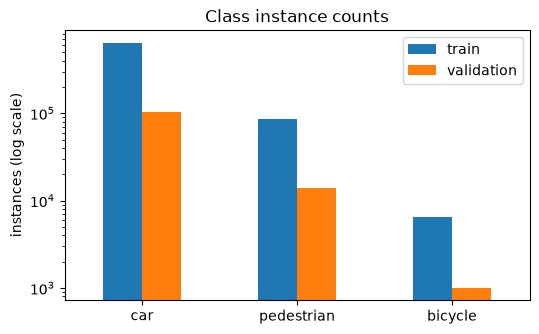

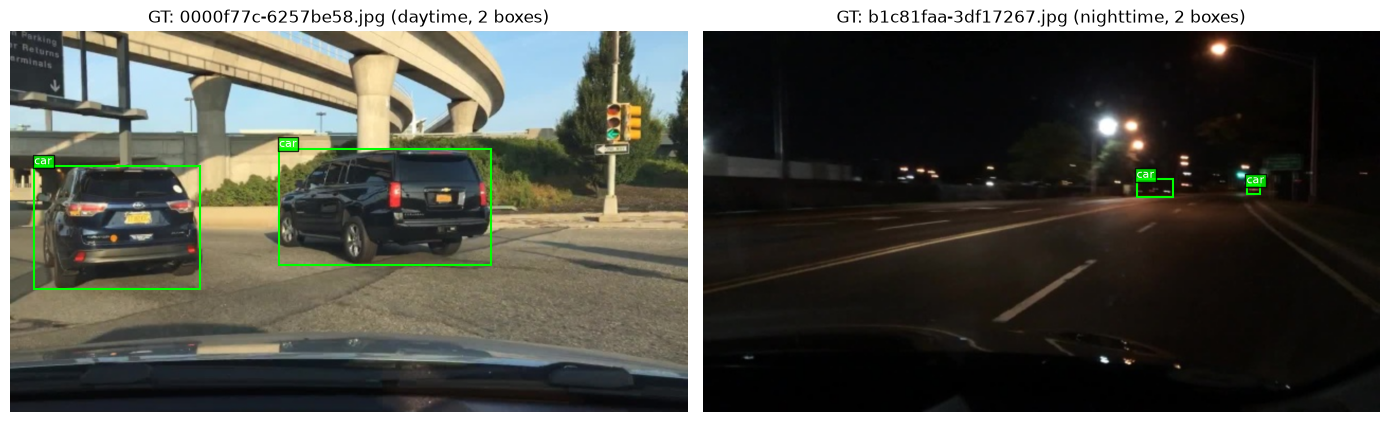

In [10]:
train_counts = train_full.class_counts()[0]
val_counts = val_full.class_counts()[0]

# Instance counts per class in both splits
counts_df = pd.DataFrame({'train': train_counts, 'validation': val_counts}).reindex(list(CLASS_NAMES))
counts_df['train %'] = (100 * counts_df['train'] / counts_df['train'].sum()).round(2)
counts_df['validation %'] = (100 * counts_df['validation'] / counts_df['validation'].sum()).round(2)
display(counts_df)

fig, ax = plt.subplots(figsize=(6, 3.5))
counts_df[['train', 'validation']].plot.bar(ax=ax, logy=True, rot=0)
ax.set_ylabel('instances (log scale)')
ax.set_title('Class instance counts')
plt.show()

# Two examples with ground-truth boxes: a training image and a nighttime validation image
night_idx = night_val.active_indices[0]
examples = [train_full[0][1], val_full.view(indices=[night_idx])[0][1]]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, sample_target in zip(axes, examples):
    sample_image = Image.open(sample_target["image_path"])
    visualize_detections_and_masks(
        image=sample_image,
        boxes=sample_target["orig_boxes"],
        labels=sample_target["labels"],
        color="lime",
        ax=ax,
    )
    ax.set_title(f"GT: {sample_target['file_name']} ({sample_target['timeofday']}, {len(sample_target['labels'])} boxes)")
plt.tight_layout()
plt.show()


**Question:** Briefly comment on the class imbalance.

**Your Answer:** The data is heavily imbalanced. Cars make up about 87% of boxes (642k train), pedestrians about 12% (86k) and bicycles under 1% (6.4k), a roughly 100:1 ratio between car and bicycle. Train and validation splits have the same proportions. A detector trained naively will therefore be dominated by the car class and will do worst on bicycles (our bicycle AP is about 12 versus 41 for car). I used focal loss in the classification term so that easy car/background examples are down-weighted, and I report per-class AP rather than only the mean so that rare-class weakness is visible.

### 1.3 Preprocessing, Random Seeds, & Training Budget
Configure your hyperparameters and training budget below. 

* **`FAST_MODE`**: Set to `True` for rapid code development and pipeline verification on small subsets. When ready to generate your final report results, set `FAST_MODE = False`.
* **`BATCH_SIZE` Tuning**:
  * Default is **`32`** (the sweet spot for most GPUs).
  * **Turn it DOWN** (to `16` or `8`) if you run out of GPU memory (CUDA OOM).
  * **Turn it UP** (to `64`) on high-VRAM Google Colab GPUs. If increasing to 64 runs slower on your machine, turn it back down to `32`.
  * *Note:* If you change `BATCH_SIZE`, scale `LEARNING_RATE` roughly proportionally (e.g., `1e-3` for 8, `2e-3` for 32).


In [11]:
# ==============================================================================
# Training Configuration & Hyperparameters
# ==============================================================================
SEED = 328
set_seeds(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Toggle FAST_MODE: True for rapid development; False for full evaluation and final report results.
FAST_MODE = False

# Batch Size: default is 32.
# - Turn DOWN (to 16 or 8) if you get Out-of-Memory (OOM) errors.
# - Turn UP (to 64) on high-VRAM Colab GPUs. If it runs slower, turn it back down to 32.
BATCH_SIZE = 32

# Learning rate: scale roughly proportionally with BATCH_SIZE (e.g., 1e-3 for BS=8, 2e-3 for BS=32)
LEARNING_RATE = 2e-3

# Multi-process data prefetching: 2 workers by default for high throughput without IPC thrashing
WORKERS = min(8, os.cpu_count() or 2) if hasattr(os, 'fork') else 0

# Dataset splits based on FAST_MODE
if FAST_MODE:
    EPOCHS = 5
    FAST_TRAIN_IMAGES = 120
    CURVE_VAL_IMAGES = 40
    FAST_EVAL_IMAGES = 60
    train_curve_base = sample_view(train_full, FAST_TRAIN_IMAGES, seed=SEED)
    curve_val = sample_view(val_full, CURVE_VAL_IMAGES, seed=SEED + 1)
    val_eval = sample_view(val_full, FAST_EVAL_IMAGES, seed=SEED + 2)
    day_eval = val_eval.view(timeofday='daytime')
    night_eval = val_eval.view(timeofday='nighttime')
else:
    EPOCHS = 15
    CURVE_VAL_IMAGES = 1000
    train_curve_base = train_full.view(indices=train_full.active_indices)
    curve_val = sample_view(val_full, CURVE_VAL_IMAGES, seed=SEED + 1)
    val_eval = val_full
    day_eval = day_val
    night_eval = night_val

train_baseline = BDD100KDataset(
    TRAIN_JSON, TRAIN_IMAGES, horizontal_flip=True, lighting_augmentation=False,
    normalize=False,
).view(indices=train_curve_base.active_indices)

train_loader = DataLoader(
    train_baseline, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=WORKERS, pin_memory=(WORKERS > 0),
    persistent_workers=(WORKERS > 0), collate_fn=collate_batch
)
curve_val_loader = DataLoader(
    curve_val, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=WORKERS, pin_memory=(WORKERS > 0),
    persistent_workers=(WORKERS > 0), collate_fn=collate_batch
)
print(f'fit images={len(train_baseline):,}; curve validation images={len(curve_val):,}; eval images={len(val_eval):,}; FAST_MODE={FAST_MODE}; EPOCHS={EPOCHS}; BATCH_SIZE={BATCH_SIZE}; WORKERS={WORKERS}')


fit images=63,000; curve validation images=1,000; eval images=10,000; FAST_MODE=False; EPOCHS=15; BATCH_SIZE=32; WORKERS=8


### 1.4 Implement Object Detector
Implement a small neural network in PyTorch for object detection. Your detector must return boxes, class labels, and confidence scores. Implement the prediction heads and training logic yourself using any architecture discussed in the lecture (such as YOLO or FCOS). Save your baseline checkpoint.

In [12]:
# ------------------------------------------------------------------------------
# Detector design: FCOS-style anchor-free one-stage detector, trained from scratch.
#   backbone (ResNet-like, strides 8/16/32) -> small FPN -> shared conv head that predicts,
#   at every feature-map location: class logits, (left, top, right, bottom) distances, centerness.
# ------------------------------------------------------------------------------
STRIDES = (8, 16, 32)
# Largest point-to-box-edge distance (pixels) each pyramid level is responsible for
REGRESS_RANGES = ((0, 64), (64, 128), (128, 1e8))

def conv_bn(c_in, c_out, k=3, s=1):
    return nn.Sequential(nn.Conv2d(c_in, c_out, k, s, k // 2, bias=False), nn.BatchNorm2d(c_out), nn.SiLU(inplace=True))

def conv_gn(c):
    return nn.Sequential(nn.Conv2d(c, c, 3, 1, 1, bias=False), nn.GroupNorm(16, c), nn.SiLU(inplace=True))

class ResBlock(nn.Module):
    # Bottleneck residual block: 1x1 reduce -> 3x3 -> identity skip
    def __init__(self, c):
        super().__init__()
        self.body = nn.Sequential(conv_bn(c, c // 2, 1), conv_bn(c // 2, c, 3))

    def forward(self, x):
        return x + self.body(x)

class Scale(nn.Module):
    # Learnable per-level scalar applied to the box-regression logits
    def __init__(self, init=1.0):
        super().__init__()
        self.scale = nn.Parameter(torch.tensor(float(init)))

    def forward(self, x):
        return x * self.scale

class StudentDetector(nn.Module):
    def __init__(self, num_classes=len(CLASS_NAMES), width=128):
        super().__init__()
        self.num_classes = num_classes

        def stage(c_in, c_out, n):
            return nn.Sequential(conv_bn(c_in, c_out, 3, 2), *[ResBlock(c_out) for _ in range(n)])

        self.stem = conv_bn(3, 32, 3, 2)          # stride 2
        self.stage4 = stage(32, 64, 1)            # stride 4
        self.stage8 = stage(64, 128, 3)           # stride 8   -> P3
        self.stage16 = stage(128, 256, 4)         # stride 16  -> P4
        self.stage32 = stage(256, 512, 2)         # stride 32  -> P5
        self.lateral = nn.ModuleList([nn.Conv2d(c, width, 1) for c in (128, 256, 512)])
        self.smooth = nn.ModuleList([conv_bn(width, width, 3) for _ in range(2)])
        self.cls_tower = nn.Sequential(conv_gn(width), conv_gn(width))
        self.reg_tower = nn.Sequential(conv_gn(width), conv_gn(width))
        self.cls_pred = nn.Conv2d(width, num_classes, 3, 1, 1)
        self.reg_pred = nn.Conv2d(width, 4, 3, 1, 1)
        self.ctr_pred = nn.Conv2d(width, 1, 3, 1, 1)
        self.scales = nn.ModuleList([Scale(1.0) for _ in STRIDES])
        # Start with a low foreground probability (0.01) so the focal loss is stable at the beginning
        nn.init.normal_(self.cls_pred.weight, std=0.01)
        nn.init.constant_(self.cls_pred.bias, -math.log(99.0))
        self._grid_cache = {}

    def _grid(self, shapes, device):
        # Feature-map cell centres in letterboxed pixel coordinates, plus per-cell stride / regression range
        key = (tuple(shapes), str(device))
        if key not in self._grid_cache:
            pts, strides, lo, hi = [], [], [], []
            for (h, w), s, (a, b) in zip(shapes, STRIDES, REGRESS_RANGES):
                ys, xs = torch.meshgrid(torch.arange(h, device=device), torch.arange(w, device=device), indexing='ij')
                pts.append(torch.stack([(xs.reshape(-1) + 0.5) * s, (ys.reshape(-1) + 0.5) * s], dim=1).float())
                strides.append(torch.full((h * w,), float(s), device=device))
                lo.append(torch.full((h * w,), float(a), device=device))
                hi.append(torch.full((h * w,), float(b), device=device))
            self._grid_cache[key] = tuple(torch.cat(v) for v in (pts, strides, lo, hi))
        return self._grid_cache[key]

    def forward(self, images):
        # images may be uint8 [0, 255] or float32; auto-normalize on GPU if uint8:
        if images.dtype == torch.uint8:
            mean = torch.tensor([0.485, 0.456, 0.406], device=images.device, dtype=torch.float32).view(1, 3, 1, 1)
            std = torch.tensor([0.229, 0.224, 0.225], device=images.device, dtype=torch.float32).view(1, 3, 1, 1)
            images = images.to(torch.float32).div_(255.0).sub_(mean).div_(std)

        c8 = self.stage8(self.stage4(self.stem(images)))
        c16 = self.stage16(c8)
        c32 = self.stage32(c16)
        p5 = self.lateral[2](c32)
        p4 = self.smooth[1](self.lateral[1](c16) + F.interpolate(p5, size=c16.shape[-2:], mode='nearest'))
        p3 = self.smooth[0](self.lateral[0](c8) + F.interpolate(p4, size=c8.shape[-2:], mode='nearest'))

        cls_out, reg_out, ctr_out, shapes = [], [], [], []
        for level, (feat, stride) in enumerate(zip((p3, p4, p5), STRIDES)):
            cls_feat, reg_feat = self.cls_tower(feat), self.reg_tower(feat)
            cls_out.append(self.cls_pred(cls_feat).flatten(2).transpose(1, 2))
            ctr_out.append(self.ctr_pred(reg_feat).flatten(2).transpose(1, 2))
            # distances (l, t, r, b) in pixels; exp keeps them positive
            reg = self.scales[level](self.reg_pred(reg_feat)).float().clamp(-8, 6)
            reg_out.append(torch.exp(reg).flatten(2).transpose(1, 2) * stride)
            shapes.append(feat.shape[-2:])

        points, strides, lo, hi = self._grid(shapes, images.device)
        return {'cls': torch.cat(cls_out, 1), 'reg': torch.cat(reg_out, 1), 'ctr': torch.cat(ctr_out, 1).squeeze(-1),
                'points': points, 'strides': strides, 'lo': lo, 'hi': hi}

    @torch.inference_mode()
    def predict(self, images, score_threshold=0.02, nms_iou=0.6, pre_nms_topk=1000, max_detections=100):
        # Returns a list (one per image) of {'boxes': N x 4 xyxy in 640x384 letterboxed pixels, 'labels': N, 'scores': N}
        was_training = self.training
        self.eval()
        with torch.autocast('cuda', dtype=torch.bfloat16, enabled=images.is_cuda):
            raw = self.forward(images)
        if was_training:
            self.train()
        H, W = images.shape[-2:]
        # final score = geometric mean of class probability and predicted centerness
        scores_all = (raw['cls'].float().sigmoid() * raw['ctr'].float().sigmoid().unsqueeze(-1)).sqrt()
        reg, pts = raw['reg'].float(), raw['points']
        results = []
        for i in range(images.shape[0]):
            s = scores_all[i].flatten()
            idx = (s > score_threshold).nonzero().squeeze(1)
            sc = s[idx]
            if sc.numel() > pre_nms_topk:
                sc, order = sc.topk(pre_nms_topk)
                idx = idx[order]
            loc, lab = idx // self.num_classes, idx % self.num_classes
            d, p = reg[i][loc], pts[loc]
            boxes = torch.stack([p[:, 0] - d[:, 0], p[:, 1] - d[:, 1], p[:, 0] + d[:, 2], p[:, 1] + d[:, 3]], dim=1)
            boxes[:, [0, 2]] = boxes[:, [0, 2]].clamp(0, W)
            boxes[:, [1, 3]] = boxes[:, [1, 3]].clamp(0, H)
            keep = torchvision.ops.batched_nms(boxes, sc, lab, iou_threshold=nms_iou)[:max_detections]
            results.append({'boxes': boxes[keep], 'labels': lab[keep], 'scores': sc[keep]})
        return results

def detection_loss(raw_outputs, targets, center_radius=1.5, alpha=0.25, gamma=2.0, loc_weight=2.0):
    # FCOS target assignment: a location is positive for a GT box if it lies near the box centre
    # (within center_radius * stride), inside the box, and the box size matches the level's regression range.
    # If several GTs claim a location, the smallest box wins.
    cls_logits, reg = raw_outputs['cls'].float(), raw_outputs['reg'].float()
    ctr_logits = raw_outputs['ctr'].float()
    pts, strides, lo, hi = (raw_outputs[k] for k in ('points', 'strides', 'lo', 'hi'))
    B, N, C = cls_logits.shape
    dev = cls_logits.device

    M = max(1, max(len(tg['boxes']) for tg in targets))
    gt_boxes = torch.zeros(B, M, 4, device=dev)
    gt_labels = torch.zeros(B, M, dtype=torch.long, device=dev)
    valid = torch.zeros(B, M, dtype=torch.bool, device=dev)
    for i, tg in enumerate(targets):
        m = len(tg['boxes'])
        if m:
            gt_boxes[i, :m], gt_labels[i, :m], valid[i, :m] = tg['boxes'].to(dev), tg['labels'].to(dev), True

    px, py = pts[None, :, 0, None], pts[None, :, 1, None]                  # [1, N, 1]
    x1, y1, x2, y2 = (gt_boxes[:, None, :, k] for k in range(4))           # [B, 1, M]
    l, t, r, b = px - x1, py - y1, x2 - px, y2 - py                        # [B, N, M]
    min_edge = torch.minimum(torch.minimum(l, t), torch.minimum(r, b))
    max_edge = torch.maximum(torch.maximum(l, t), torch.maximum(r, b))
    radius = center_radius * strides[None, :, None]
    in_center = ((px - (x1 + x2) / 2).abs() < radius) & ((py - (y1 + y2) / 2).abs() < radius)
    in_range = (max_edge >= lo[None, :, None]) & (max_edge <= hi[None, :, None])
    candidate = (min_edge > 0) & in_center & in_range & valid[:, None, :]
    area = ((x2 - x1) * (y2 - y1)).expand(-1, N, -1)
    min_area, min_idx = torch.where(candidate, area, torch.full_like(area, float('inf'))).min(dim=2)   # [B, N]
    pos = torch.isfinite(min_area)
    num_pos = pos.sum().clamp(min=1).float()

    # Classification: sigmoid focal loss over all locations
    cls_target = torch.zeros_like(cls_logits)
    cls_target[pos] = F.one_hot(gt_labels.gather(1, min_idx)[pos], C).float()
    p = cls_logits.sigmoid()
    ce = F.binary_cross_entropy_with_logits(cls_logits, cls_target, reduction='none')
    p_t = p * cls_target + (1 - p) * (1 - cls_target)
    a_t = alpha * cls_target + (1 - alpha) * (1 - cls_target)
    focal = (a_t * (1 - p_t) ** gamma * ce).sum() / num_pos

    # Localization: GIoU on positive locations, weighted by the centerness target
    box = gt_boxes.gather(1, min_idx[..., None].expand(-1, -1, 4))[pos]    # [P, 4]
    pp = pts[None].expand(B, -1, -1)[pos]                                  # [P, 2]
    tl = torch.stack([pp[:, 0] - box[:, 0], pp[:, 1] - box[:, 1], box[:, 2] - pp[:, 0], box[:, 3] - pp[:, 1]], dim=1)
    pl = reg[pos]
    ctr_target = torch.sqrt((torch.minimum(tl[:, 0], tl[:, 2]) / torch.maximum(tl[:, 0], tl[:, 2]).clamp(min=1e-6)) *
                            (torch.minimum(tl[:, 1], tl[:, 3]) / torch.maximum(tl[:, 1], tl[:, 3]).clamp(min=1e-6)))
    # predicted and target boxes share the same anchor point, so GIoU can be computed from the distances directly
    inter = (torch.minimum(pl[:, 0], tl[:, 0]) + torch.minimum(pl[:, 2], tl[:, 2])) * \
            (torch.minimum(pl[:, 1], tl[:, 1]) + torch.minimum(pl[:, 3], tl[:, 3]))
    union = (pl[:, 0] + pl[:, 2]) * (pl[:, 1] + pl[:, 3]) + (tl[:, 0] + tl[:, 2]) * (tl[:, 1] + tl[:, 3]) - inter
    enclose = (torch.maximum(pl[:, 0], tl[:, 0]) + torch.maximum(pl[:, 2], tl[:, 2])) * \
              (torch.maximum(pl[:, 1], tl[:, 1]) + torch.maximum(pl[:, 3], tl[:, 3]))
    giou = inter / union.clamp(min=1e-6) - (enclose - union) / enclose.clamp(min=1e-6)
    localization = ((1 - giou) * ctr_target).sum() / ctr_target.sum().clamp(min=1e-6)
    centerness = F.binary_cross_entropy_with_logits(ctr_logits[pos], ctr_target, reduction='sum') / num_pos

    classification = focal + centerness
    return {'classification': classification, 'localization': localization, 'total': classification + loc_weight * localization}


### 1.5 Train Detector
Train your model. Plot the training losses (classification vs. localization) and validation AP across epochs.

In [13]:
import contextlib
import io

def train_detector(model, train_loader, curve_dataset, epochs, learning_rate, output_path):
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=0.05)
    history = {'classification_loss': [], 'localization_loss': [], 'val_AP': [], 'val_AP50': []}
    best_ap = -1.0
    use_amp = DEVICE.type == 'cuda'

    # Linear warm-up followed by cosine decay
    total_steps = epochs * len(train_loader)
    warmup_steps = max(1, min(500, total_steps // 10))
    def lr_lambda(step):
        warm = min(1.0, (step + 1) / warmup_steps)
        cosine = 0.5 * (1 + math.cos(math.pi * min(1.0, step / max(1, total_steps))))
        return warm * (0.02 + 0.98 * cosine)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

    # Exponential moving average of the weights: smoother and usually better than the raw weights
    ema = copy.deepcopy(model).eval()
    for p in ema.parameters():
        p.requires_grad_(False)
    step = 0

    for epoch in range(epochs):
        model.train()
        cls_sum, loc_sum, n_batches = 0.0, 0.0, 0
        pbar = tqdm(train_loader, desc=f"Epoch {epoch + 1:02d}/{epochs:02d} [Train]", leave=True)
        for images, targets in pbar:
            images = images.to(DEVICE, non_blocking=True)
            if images.dtype == torch.uint8:
                mean = torch.tensor([0.485, 0.456, 0.406], device=DEVICE, dtype=torch.float32).view(1, 3, 1, 1)
                std = torch.tensor([0.229, 0.224, 0.225], device=DEVICE, dtype=torch.float32).view(1, 3, 1, 1)
                images = images.to(torch.float32).div_(255.0).sub_(mean).div_(std)
            gt = [{'boxes': t['boxes'].to(DEVICE), 'labels': t['labels'].to(DEVICE)} for t in targets]

            with torch.autocast('cuda', dtype=torch.bfloat16, enabled=use_amp):
                raw = model(images)
            losses = detection_loss(raw, gt)   # computed in float32

            optimizer.zero_grad(set_to_none=True)
            losses['total'].backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
            optimizer.step()
            scheduler.step()

            decay = min(0.999, (1 + step) / (10 + step))
            with torch.no_grad():
                msd = model.state_dict()
                for k, v in ema.state_dict().items():
                    if v.dtype.is_floating_point:
                        v.mul_(decay).add_(msd[k].detach(), alpha=1 - decay)
                    else:
                        v.copy_(msd[k])
            step += 1

            cls_sum += losses['classification'].item()
            loc_sum += losses['localization'].item()
            n_batches += 1
            pbar.set_postfix(cls=f'{cls_sum / n_batches:.3f}', loc=f'{loc_sum / n_batches:.3f}')

        history['classification_loss'].append(cls_sum / max(1, n_batches))
        history['localization_loss'].append(loc_sum / max(1, n_batches))

        # Validation AP on the curve subset (using the EMA weights); keep the best checkpoint
        preds = collect_predictions(ema, curve_dataset, DEVICE, batch_size=BATCH_SIZE, workers=0, desc='Validating')
        with contextlib.redirect_stdout(io.StringIO()):
            result = evaluate_coco(curve_dataset, preds, iou_type='bbox')
        ap, ap50 = max(result['AP'], 0.0), max(result['AP50'], 0.0)
        history['val_AP'].append(ap)
        history['val_AP50'].append(ap50)
        if ap > best_ap:
            best_ap = ap
            torch.save(ema.state_dict(), output_path)
        print(f'Epoch {epoch + 1}/{epochs}: cls={history["classification_loss"][-1]:.4f} loc={history["localization_loss"][-1]:.4f} '
              f'val AP={ap:.4f} AP50={ap50:.4f} (best AP={best_ap:.4f})')

    # Return the best saved weights
    model.load_state_dict(torch.load(output_path, map_location=DEVICE))
    del optimizer, ema
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return model, history

# Instantiate your model and run training.
set_seeds(SEED)
detector = StudentDetector().to(DEVICE)
print(f'parameters: {sum(p.numel() for p in detector.parameters()) / 1e6:.2f}M')
detector, baseline_history = train_detector(detector, train_loader, curve_val, EPOCHS, LEARNING_RATE, OUTPUT_DIR / 'baseline_detector.pt')

# Release training DataLoader workers and memory buffers
del train_loader, train_baseline
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


parameters: 6.79M


Epoch 01/15 [Train]: 100%|██████████| 1969/1969 [03:04<00:00, 10.66it/s, cls=0.844, loc=0.333]


Epoch 1/15: cls=0.8435 loc=0.3328 val AP=0.1608 AP50=0.3206 (best AP=0.1608)


Epoch 02/15 [Train]: 100%|██████████| 1969/1969 [02:52<00:00, 11.43it/s, cls=0.768, loc=0.254]


Epoch 2/15: cls=0.7682 loc=0.2544 val AP=0.1899 AP50=0.3701 (best AP=0.1899)


Epoch 03/15 [Train]: 100%|██████████| 1969/1969 [02:52<00:00, 11.43it/s, cls=0.755, loc=0.240]


... (21 outputs left out)

Epoch 14/15 [Train]: 100%|██████████| 1969/1969 [02:52<00:00, 11.44it/s, cls=0.698, loc=0.179]


Epoch 14/15: cls=0.6985 loc=0.1791 val AP=0.2327 AP50=0.4624 (best AP=0.2365)


Epoch 15/15 [Train]: 100%|██████████| 1969/1969 [02:53<00:00, 11.37it/s, cls=0.696, loc=0.177]


Epoch 15/15: cls=0.6964 loc=0.1768 val AP=0.2323 AP50=0.4626 (best AP=0.2365)


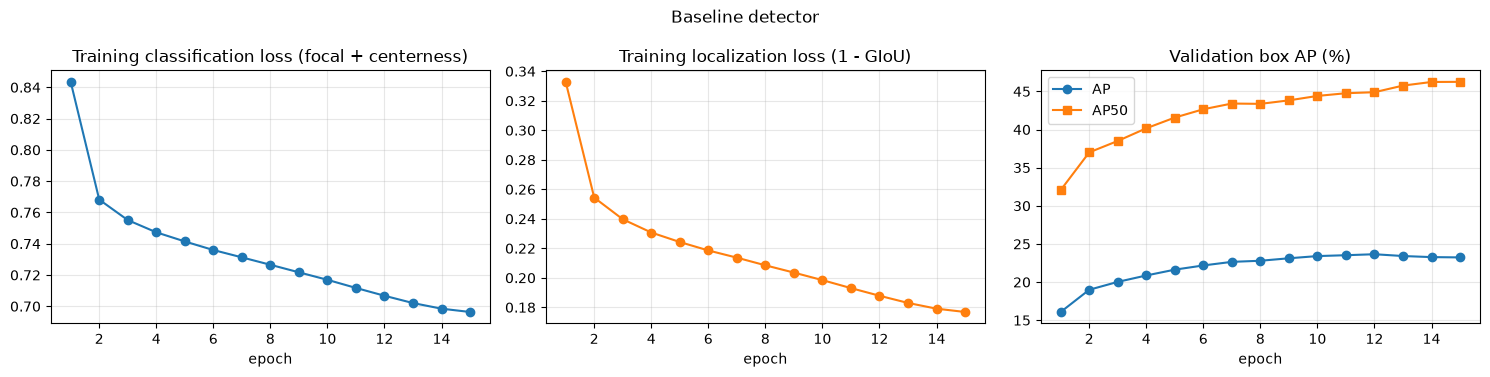

In [14]:
def plot_history(history, title):
    epochs_axis = range(1, len(history['val_AP']) + 1)
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
    axes[0].plot(epochs_axis, history['classification_loss'], marker='o')
    axes[0].set_title('Training classification loss (focal + centerness)')
    axes[1].plot(epochs_axis, history['localization_loss'], marker='o', color='tab:orange')
    axes[1].set_title('Training localization loss (1 - GIoU)')
    axes[2].plot(epochs_axis, [100 * a for a in history['val_AP']], marker='o', label='AP')
    axes[2].plot(epochs_axis, [100 * a for a in history['val_AP50']], marker='s', label='AP50')
    axes[2].set_title('Validation box AP (%)')
    axes[2].legend()
    for ax in axes:
        ax.set_xlabel('epoch')
        ax.grid(alpha=0.3)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_history(baseline_history, 'Baseline detector')

> **Now That Your Pipeline Works — Disable `FAST_MODE` and Retrain:**
> If you used `FAST_MODE = True` to develop and verify that your model, losses, and training loop run without errors, **return to Section 1.3, set `FAST_MODE = False`, and retrain your model** (preferably using a GPU runtime in Google Colab). Full training ensures your baseline model, nighttime improvements, AP scores, and precision/recall metrics are valid for your final report.

**Question:** Discuss the model's training behaviour. Does it appear to be learning effectively?

**Your Answer:** Yes. Over 15 epochs the classification loss fell from 0.84 to 0.70 and the localization loss from 0.33 to 0.18, and both decreased smoothly with no divergence. Validation AP rose quickly (16.1 after epoch 1, 21.6 at epoch 5) and kept improving slowly to a best of 23.65 at epoch 12 (AP50 about 45). In the last three epochs AP flattened or dipped slightly (23.4, 23.3, 23.2) while AP50 and the training loss kept improving, which suggests the model is close to saturating at this capacity and schedule, with mild overfitting of box tightness. I kept the best-AP EMA checkpoint. The model passes the targets (AP >= 14, AP50 >= 30) from epoch 1.

### 1.6 YOLO26 Detection Reference Setup
Import YOLO26 from the ultralytics package. Document which size you chose.

In [15]:
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

from ultralytics import YOLO

# YOLO26-medium: a good accuracy / speed trade-off that runs comfortably on a Colab GPU
YOLO_DET_WEIGHTS = 'yolo26m.pt'
yolo_detector = YOLO(YOLO_DET_WEIGHTS)
print('Reference checkpoint:', YOLO_DET_WEIGHTS, '| parameters:', f'{sum(p.numel() for p in yolo_detector.model.parameters()) / 1e6:.1f}M')

Reference checkpoint: yolo26m.pt | parameters: 21.9M


**Question:** Which YOLO26 model size did you select, and why?

**Your Answer:** I selected YOLO26m (yolo26m.pt, about 22M parameters). It is a middle size: noticeably more accurate than the n/s variants, but far cheaper than l/x, so evaluating 10,000 validation images on one 16 GB GPU stays fast. It gives a strong reference point without being so large that the comparison with our 6.8M-parameter from-scratch detector becomes meaningless. Only the person, bicycle and car COCO classes are kept and mapped to the BDD classes.

### 1.7 Evaluate Detection AP (Daytime and Nighttime)
Evaluate your detector and YOLO26 on the daytime and nighttime validation subsets using the COCO evaluator. Report Box AP, AP50, and per-class AP, as well as the daytime vs. nighttime gap.

In [16]:
student_preds = collect_predictions(detector, val_eval, DEVICE, batch_size=BATCH_SIZE)
day_ids = set(int(i) for i in day_eval.active_indices)
night_ids = set(int(i) for i in night_eval.active_indices)

def evaluate_splits(preds, name):
    # Box AP / AP50 and per-class AP on the full, daytime and nighttime validation sets
    rows = []
    for split, ds, ids in (('Full', val_eval, None), ('Daytime', day_eval, day_ids), ('Nighttime', night_eval, night_ids)):
        subset = preds if ids is None else [p for p in preds if int(p['image_id']) in ids]
        with contextlib.redirect_stdout(io.StringIO()):
            res = evaluate_coco(ds, subset, iou_type='bbox')
        row = {'model': name, 'split': split, 'images': len(ds), 'AP': 100 * res['AP'], 'AP50': 100 * res['AP50']}
        row.update({f'AP {c}': 100 * res['per_class'][c]['AP'] for c in CLASS_NAMES})
        rows.append(row)
    return pd.DataFrame(rows)

student_results = evaluate_splits(student_preds, 'StudentDetector (baseline)')

# Free GPU cache before running YOLO evaluation
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# YOLO26 reference: COCO ids person=0, bicycle=1, car=2 -> BDD ids pedestrian=1, bicycle=2, car=0
COCO_TO_BDD = torch.tensor([1, 2, 0])

def collect_yolo_predictions(yolo, dataset, batch_size=32):
    # The dataset images are already letterboxed to 640x384, so YOLO boxes are in letterboxed space;
    # inverse_letterbox_boxes maps them back to the original 1280x720 coordinates used by evaluate_coco.
    ds = copy.copy(dataset)
    ds.normalize = False
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=WORKERS, collate_fn=collate_batch)
    collected = []
    for _, targets in tqdm(loader, desc='YOLO26 predict', leave=False):
        results = yolo.predict([t['image_path'] for t in targets], imgsz=640, conf=0.001, iou=0.7, max_det=100,
                               classes=[0, 1, 2], half=DEVICE.type == 'cuda', verbose=False, device=DEVICE)
        for res, target in zip(results, targets):
            boxes = res.boxes.xyxy.cpu().float()
            collected.append({
                'image_id': target['image_id'],
                'boxes': inverse_letterbox_boxes(boxes, target),
                'labels': COCO_TO_BDD[res.boxes.cls.cpu().long()],
                'scores': res.boxes.conf.cpu().float(),
                'timeofday': target['timeofday'],
                'file_name': target['file_name'],
            })
    return collected

yolo_preds = collect_yolo_predictions(yolo_detector, val_eval)
yolo_results = evaluate_splits(yolo_preds, f'YOLO26 ({YOLO_DET_WEIGHTS})')

detection_ap_table = pd.concat([student_results, yolo_results], ignore_index=True)
display(detection_ap_table.round(2))

for name, res in (('StudentDetector', student_results), ('YOLO26', yolo_results)):
    day_ap, night_ap = res.set_index('split').loc['Daytime', 'AP'], res.set_index('split').loc['Nighttime', 'AP']
    print(f'{name}: day AP={day_ap:.2f}, night AP={night_ap:.2f}, gap (day - night)={day_ap - night_ap:.2f} AP points')

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


YOLO26 predict:   0%|          | 0/313 [00:00<?, ?it/s]

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


YOLO26 predict:   0%|          | 1/313 [00:04<22:09,  4.26s/it]

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


YOLO26 predict:   1%|          | 2/313 [00:04<09:32,  1.84s/it]

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


... (618 outputs left out)

YOLO26 predict: 100%|█████████▉| 312/313 [00:42<00:00,  8.66it/s]

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


,model,split,images,AP,AP50,AP car,AP pedestrian,AP bicycle
0,StudentDetector (baseline),Full,10000,24.69,48.40,40.92,21.25,11.89
1,StudentDetector (baseline),Daytime,5258,25.58,49.08,42.98,21.80,11.97
2,StudentDetector (baseline),Nighttime,3929,22.55,45.88,37.22,19.49,10.94
3,YOLO26 (yolo26m.pt),Full,10000,28.53,52.70,38.52,29.13,17.95
4,YOLO26 (yolo26m.pt),Daytime,5258,30.74,55.70,43.26,30.92,18.03
5,YOLO26 (yolo26m.pt),Nighttime,3929,23.00,44.22,29.53,23.36,16.12


StudentDetector: day AP=25.58, night AP=22.55, gap (day - night)=3.04 AP points
YOLO26: day AP=30.74, night AP=23.00, gap (day - night)=7.74 AP points


### 1.8 Precision and Recall Operating Point
Report precision and recall for your detector at candidate score thresholds 0.25, 0.50, and 0.75. Choose one operating threshold using a stated validation rule (e.g., highest F1 score). Then evaluate your chosen operating detector on daytime and nighttime subsets to compare operational performance.

| Condition / Split | Threshold | Precision | Recall | F1 Score | Predictions |
| :--- | :---: | :---: | :---: | :---: | :---: |
| Full Validation | 0.25 | 0.3022 | 0.7370 | 0.4287 | 286320 |
| **Full Validation (Chosen)** | **0.50** | 0.8437 | 0.5551 | 0.6696 | 77253 |
| Full Validation | 0.75 | 0.9880 | 0.2425 | 0.3895 | 28826 |
| Daytime (Chosen) | 0.50 | 0.8640 | 0.5536 | 0.6748 | 43840 |
| Nighttime (Chosen) | 0.50 | 0.8062 | 0.5579 | 0.6594 | 27047 |

*Tip:* State which threshold you chose (e.g. bold it or label it **Chosen**) and your selection rule. Notice whether nighttime causes a drop in precision (false alarms) or a drop in recall and prediction count (missed detections in low contrast/shadows).

In [17]:
CANDIDATE_THRESHOLDS = (0.25, 0.50, 0.75)

def operating_point_table(preds, threshold=None):
    # Sweep candidate thresholds on the FULL validation set; if no threshold is given, pick the one with the highest F1.
    # Then report that operating point on the daytime and nighttime subsets.
    sweep = {th: match_precision_recall(val_eval, preds, th) for th in CANDIDATE_THRESHOLDS}
    if threshold is None:
        threshold = max(sweep, key=lambda th: sweep[th]['f1'])
    rows = [('Full Validation' + (' (Chosen)' if th == threshold else ''), th, sweep[th]) for th in CANDIDATE_THRESHOLDS]
    if threshold not in sweep:
        rows.append(('Full Validation (Chosen)', threshold, match_precision_recall(val_eval, preds, threshold)))
    rows.append(('Daytime (Chosen)', threshold, match_precision_recall(day_eval, preds, threshold)))
    rows.append(('Nighttime (Chosen)', threshold, match_precision_recall(night_eval, preds, threshold)))
    table = pd.DataFrame([{'Condition / Split': name, 'Threshold': th, 'Precision': m['precision'], 'Recall': m['recall'],
                           'F1 Score': m['f1'], 'Predictions': m['tp'] + m['fp'], 'GT boxes': m['tp'] + m['fn']}
                          for name, th, m in rows])
    return table, threshold

# Operating threshold rule: the candidate score threshold with the highest F1 on the full validation set
pr_table, OPERATING_THRESHOLD = operating_point_table(student_preds)
display(pr_table.round(4))
print(f'Chosen operating threshold = {OPERATING_THRESHOLD} (highest F1 on the full validation set)')


,Condition / Split,Threshold,Precision,Recall,F1 Score,Predictions,GT boxes
0,Full Validation,0.25,0.3022,0.7370,0.4287,286320,117424
1,Full Validation (Chosen),0.50,0.8437,0.5551,0.6696,77253,117424
2,Full Validation,0.75,0.9880,0.2425,0.3895,28826,117424
3,Daytime (Chosen),0.50,0.8640,0.5536,0.6748,43840,68428
4,Nighttime (Chosen),0.50,0.8062,0.5579,0.6594,27047,39086


Chosen operating threshold = 0.5 (highest F1 on the full validation set)


**Question:** What threshold did you choose and what validation rule did you use to justify it?

**Your Answer:** I chose a score threshold of **0.50**, using the rule of highest F1 on the full validation set. F1 was 0.429 at 0.25 (precision 0.30, recall 0.74), 0.670 at 0.50 (precision 0.84, recall 0.56) and 0.390 at 0.75 (precision 0.99, recall 0.24). 0.25 floods the output with false alarms (286k predictions for 117k GT boxes), and 0.75 misses most objects. At the chosen threshold, daytime has precision 0.864 and recall 0.554, and nighttime has precision 0.806 and recall 0.558. So night loses about 6 points of precision (more false alarms) while recall is almost unchanged.

### 1.9 Visualize Example Detections
Display several BDD100k images with true (green) and predicted (red) bounding boxes. Include correct and incorrect detections. State the gap between daytime and nighttime performance.

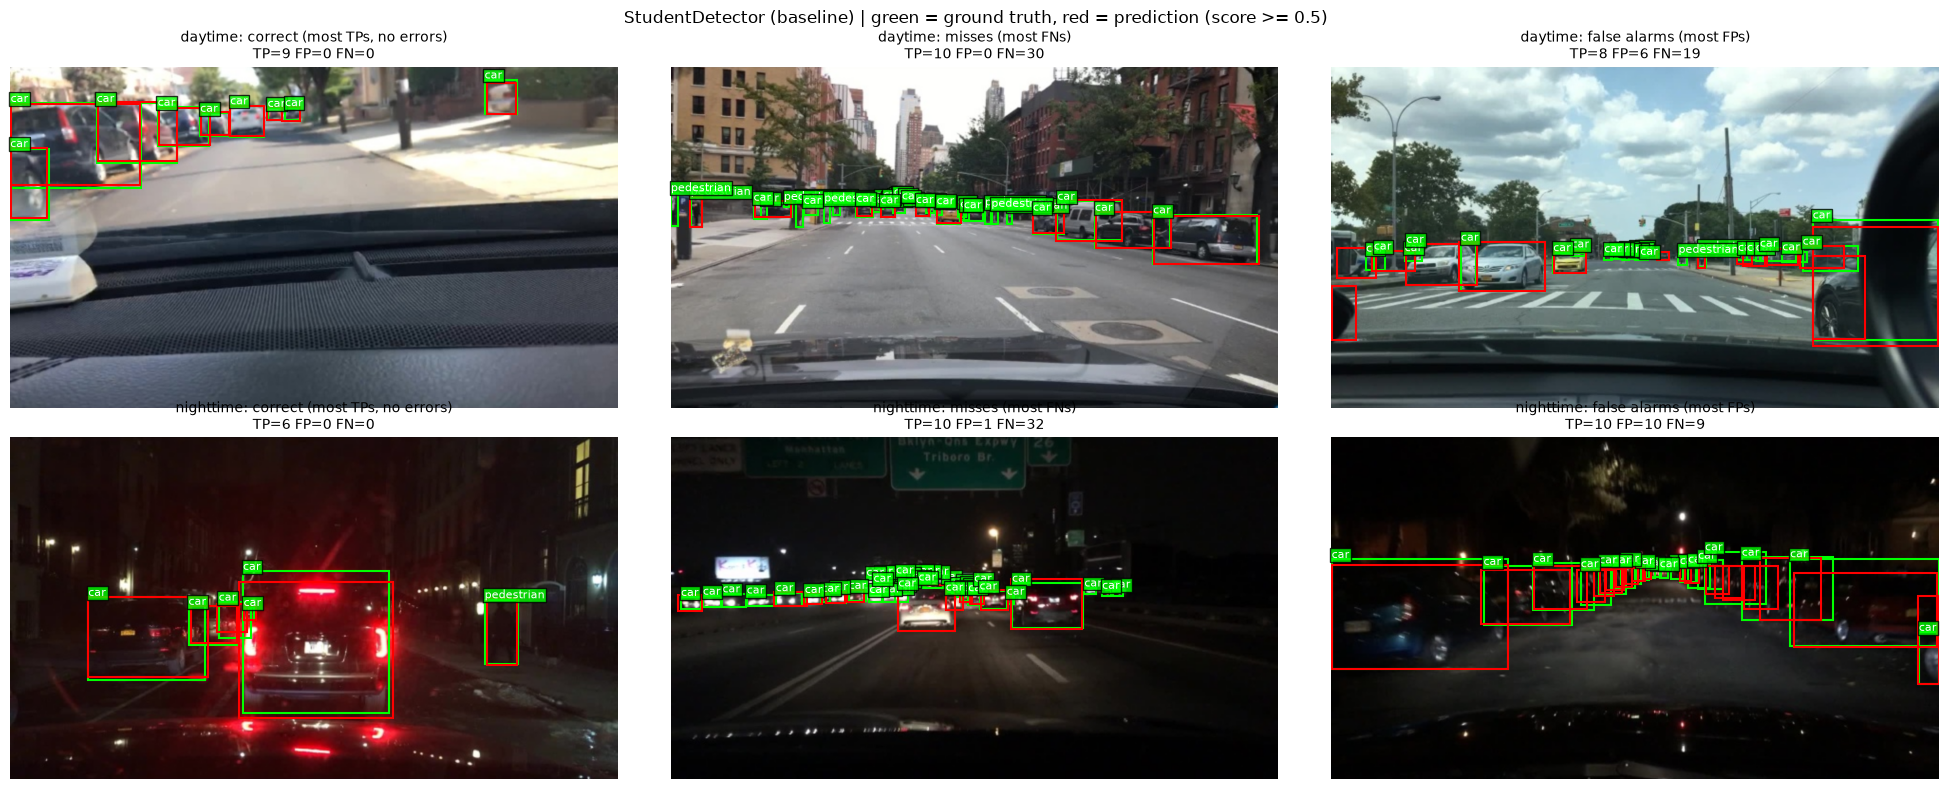

In [18]:
def load_full_res_image(path):
    # Crop the 12px letterbox padding and resize back to the original 1280x720 frame
    img = np.array(Image.open(path).convert('RGB'))[12:372]
    return np.array(Image.fromarray(img).resize((1280, 720), Image.Resampling.BILINEAR))

def per_image_errors(dataset, preds_by_image, threshold, indices):
    # (index, tp, fp, fn) for the given images at the operating threshold
    out = []
    for idx in indices:
        m = match_precision_recall(dataset.view(indices=[idx]), [preds_by_image[idx]], threshold)
        out.append((idx, m['tp'], m['fp'], m['fn']))
    return out

def show_detection_examples(dataset, preds, threshold, title):
    by_image = {int(p['image_id']): p for p in preds}
    fig, axes = plt.subplots(2, 3, figsize=(20, 8))
    for row, (tod, subset) in enumerate((('daytime', dataset.view(timeofday='daytime')), ('nighttime', dataset.view(timeofday='nighttime')))):
        # Restrict to a manageable random subset of images with enough objects to be informative
        pool = [i for i in random.Random(SEED).sample(subset.active_indices, min(400, len(subset)))
                if len(_boxes_and_labels(dataset.records[i])[1]) >= 4]
        stats = per_image_errors(dataset, by_image, threshold, pool)
        picks = {
            'correct (most TPs, no errors)': max(stats, key=lambda s: (s[2] + s[3] == 0, s[1])),
            'misses (most FNs)': max(stats, key=lambda s: s[3]),
            'false alarms (most FPs)': max(stats, key=lambda s: s[2]),
        }
        for col, (name, (idx, tp, fp, fn)) in enumerate(picks.items()):
            ax = axes[row, col]
            rec = dataset.records[idx]
            gt_boxes, gt_labels = _boxes_and_labels(rec)
            p = by_image[idx]
            keep = p['scores'] >= threshold
            img = load_full_res_image(dataset._image_path(idx))
            visualize_detections_and_masks(img, boxes=torch.tensor(gt_boxes), labels=torch.tensor(gt_labels), color='lime', ax=ax)
            for box, lab, sc in zip(p['boxes'][keep], p['labels'][keep], p['scores'][keep]):
                x1, y1, x2, y2 = box.tolist()
                ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color='red', linewidth=1.5))
            ax.set_title(f'{tod}: {name}\nTP={tp} FP={fp} FN={fn}', fontsize=10)
    fig.suptitle(title + ' | green = ground truth, red = prediction (score >= ' + str(threshold) + ')')
    plt.tight_layout()
    plt.show()

show_detection_examples(val_eval, student_preds, OPERATING_THRESHOLD, 'StudentDetector (baseline)')

**Question:** What is the AP gap between daytime and nighttime performance for your model?

**Your Answer:** My detector scores 25.58 AP on daytime and 22.55 AP on nighttime, a gap of 3.04 AP points (AP50 49.08 vs 45.88). The drop is spread across classes (car 42.98 to 37.22, pedestrian 21.80 to 19.49, bicycle 11.97 to 10.94). For comparison, YOLO26m has a larger gap of 7.74 points (30.74 vs 23.00), and at night it is only about 0.5 AP better than my detector (23.00 vs 22.55) despite being much better by day. Part of the YOLO gap is likely because it was pretrained on COCO, which is mostly daytime imagery, while my model was trained on BDD100K night images too.

### 1.10 Interpret Results
**Question:** Discuss what you observe from the evaluation metrics, precision/recall operating points, and example detections. Although high-confidence detections maintain high precision (~99%), what are the primary failure cases and performance bottlenecks for your detector at night (e.g., recall/missed detections vs. false alarms, low-contrast pedestrians, scale degradation)?

**Your Answer:** Overall the detector reaches 24.7 AP / 48.4 AP50 on the full validation set (the targets were 14 / 30), and YOLO26m reaches 28.5 / 52.7. High-confidence detections are very reliable (precision 0.99 at 0.75), but recall is the main bottleneck: only 55% of GT boxes are found at the chosen threshold and 74% even at 0.25, where precision collapses to 0.30. At night, recall is unchanged (0.558 vs 0.554) but precision falls (0.806 vs 0.864), so the night weakness shows up as more false alarms (dark regions, headlights and glare confused for objects), and lower-quality localization (AP50 drops 3.2 points, AP drops 3.0). The missed objects in the example grid tend to be small, distant or low-contrast ones (especially pedestrians and bicycles, whose AP is far below car), and heavily occluded ones, for both day and night. Class imbalance and small object scale, rather than lighting alone, limit rare-class AP.

### 1.11 Targeted Nighttime Improvement
State a hypothesis about one nighttime weakness and propose an intervention. Retrain your detector once using either lighting augmentation (e.g., brightness, contrast, and color jitter) or additional permitted nighttime images. Keep all other components and hyperparameter settings fixed.

*Hypothesis Example:* Nighttime degradation is primarily driven by loss of edge contrast and underexposure in shadows, causing the detector to produce lower confidence scores and miss unlit pedestrians and shadowed vehicles. Applying random lighting augmentation (contrast and brightness jittering) during training will improve contrast invariance, boosting nighttime recall and narrowing the day-night AP gap.

**Question:** What is your hypothesis regarding the nighttime weakness, and what change are you testing?

**Your Answer:** Hypothesis: night images are underexposed and low in contrast, with glare from lights, so the intensity statistics at night differ from the average training image, and the detector has seen relatively few dark examples for the features it needs. Training with random brightness and contrast augmentation should expose the model to a wider range of lighting and make its features more robust to it. I test this by retraining the identical model with only `lighting_augmentation=True` changed (same seed, data, epochs, optimizer and architecture), so that any change is attributable to the augmentation.

Epoch 01/15 [Train]: 100%|██████████| 1969/1969 [03:00<00:00, 10.92it/s, cls=0.849, loc=0.338]


Epoch 1/15: cls=0.8495 loc=0.3375 val AP=0.1625 AP50=0.3257 (best AP=0.1625)


Epoch 02/15 [Train]: 100%|██████████| 1969/1969 [02:59<00:00, 10.98it/s, cls=0.771, loc=0.257]


Epoch 2/15: cls=0.7714 loc=0.2574 val AP=0.1905 AP50=0.3787 (best AP=0.1905)


Epoch 03/15 [Train]: 100%|██████████| 1969/1969 [03:00<00:00, 10.91it/s, cls=0.758, loc=0.242]


Epoch 3/15: cls=0.7578 loc=0.2422 val AP=0.2000 AP50=0.3898 (best AP=0.2000)


... (20 outputs left out)

Epoch 14/15 [Train]: 100%|██████████| 1969/1969 [03:00<00:00, 10.91it/s, cls=0.702, loc=0.183]


Epoch 14/15: cls=0.7025 loc=0.1833 val AP=0.2409 AP50=0.4715 (best AP=0.2409)


Epoch 15/15 [Train]: 100%|██████████| 1969/1969 [03:00<00:00, 10.92it/s, cls=0.701, loc=0.181]


Epoch 15/15: cls=0.7006 loc=0.1812 val AP=0.2408 AP50=0.4707 (best AP=0.2409)


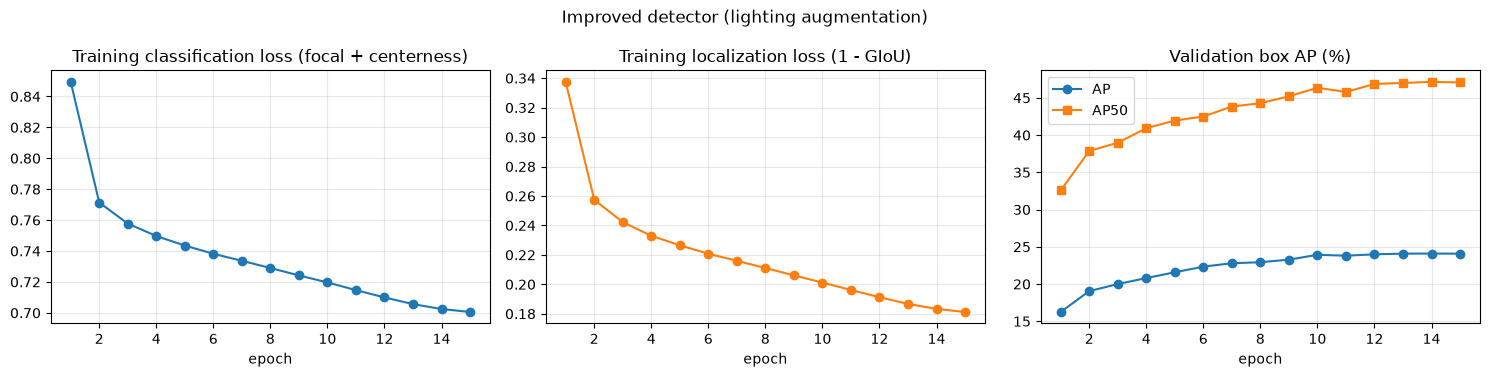

In [19]:
# Free GPU cache before retraining
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Same seed, architecture, schedule, batch size, epochs and learning rate as the baseline.
# The ONLY change: random brightness / contrast jitter (lighting augmentation) on the training images.
set_seeds(SEED)
train_improved = BDD100KDataset(
    TRAIN_JSON, TRAIN_IMAGES, horizontal_flip=True, lighting_augmentation=True, normalize=False,
).view(indices=train_curve_base.active_indices)
train_loader_improved = DataLoader(
    train_improved, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=WORKERS, pin_memory=(WORKERS > 0),
    persistent_workers=(WORKERS > 0), collate_fn=collate_batch
)
improved_detector = StudentDetector().to(DEVICE)
improved_detector, improved_history = train_detector(
    improved_detector, train_loader_improved, curve_val, EPOCHS, LEARNING_RATE, OUTPUT_DIR / 'improved_detector.pt')
plot_history(improved_history, 'Improved detector (lighting augmentation)')

del train_loader_improved, train_improved
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


### 1.12 Evaluate Improvement
Reevaluate your new "nighttime" model on the full, daytime, and nighttime validation sets using the original operating threshold.

Box AP / AP50 / per-class AP:


,model,split,images,AP,AP50,AP car,AP pedestrian,AP bicycle
0,StudentDetector (baseline),Full,10000,24.69,48.40,40.92,21.25,11.89
1,StudentDetector (baseline),Daytime,5258,25.58,49.08,42.98,21.80,11.97
2,StudentDetector (baseline),Nighttime,3929,22.55,45.88,37.22,19.49,10.94
3,StudentDetector (lighting aug),Full,10000,25.37,49.28,41.04,21.48,13.58
4,StudentDetector (lighting aug),Daytime,5258,26.28,49.83,43.07,22.04,13.74
5,StudentDetector (lighting aug),Nighttime,3929,23.02,46.72,37.36,19.51,12.19


Precision / recall at the original operating threshold (0.5):


,Condition / Split,Threshold,Precision,Recall,F1 Score,Predictions,GT boxes
0,Full Validation,0.25,0.3110,0.7390,0.4378,279042,117424
1,Full Validation (Chosen),0.50,0.8441,0.5563,0.6706,77390,117424
2,Full Validation,0.75,0.9883,0.2464,0.3945,29279,117424
3,Daytime (Chosen),0.50,0.8627,0.5546,0.6752,43989,68428
4,Nighttime (Chosen),0.50,0.8086,0.5584,0.6606,26994,39086


,split,model,AP,AP50,Precision,Recall,F1,Predictions
0,Full,baseline,24.686,48.400,0.844,0.555,0.670,77253
1,Full,lighting aug,25.366,49.276,0.844,0.556,0.671,77390
2,Daytime,baseline,25.583,49.077,0.864,0.554,0.675,43840
3,Daytime,lighting aug,26.284,49.831,0.863,0.555,0.675,43989
4,Nighttime,baseline,22.548,45.881,0.806,0.558,0.659,27047
5,Nighttime,lighting aug,23.019,46.719,0.809,0.558,0.661,26994


Daytime: AP 25.58 -> 26.28 (+0.70); recall 0.554 -> 0.555; precision 0.864 -> 0.863
Nighttime: AP 22.55 -> 23.02 (+0.47); recall 0.558 -> 0.558; precision 0.806 -> 0.809


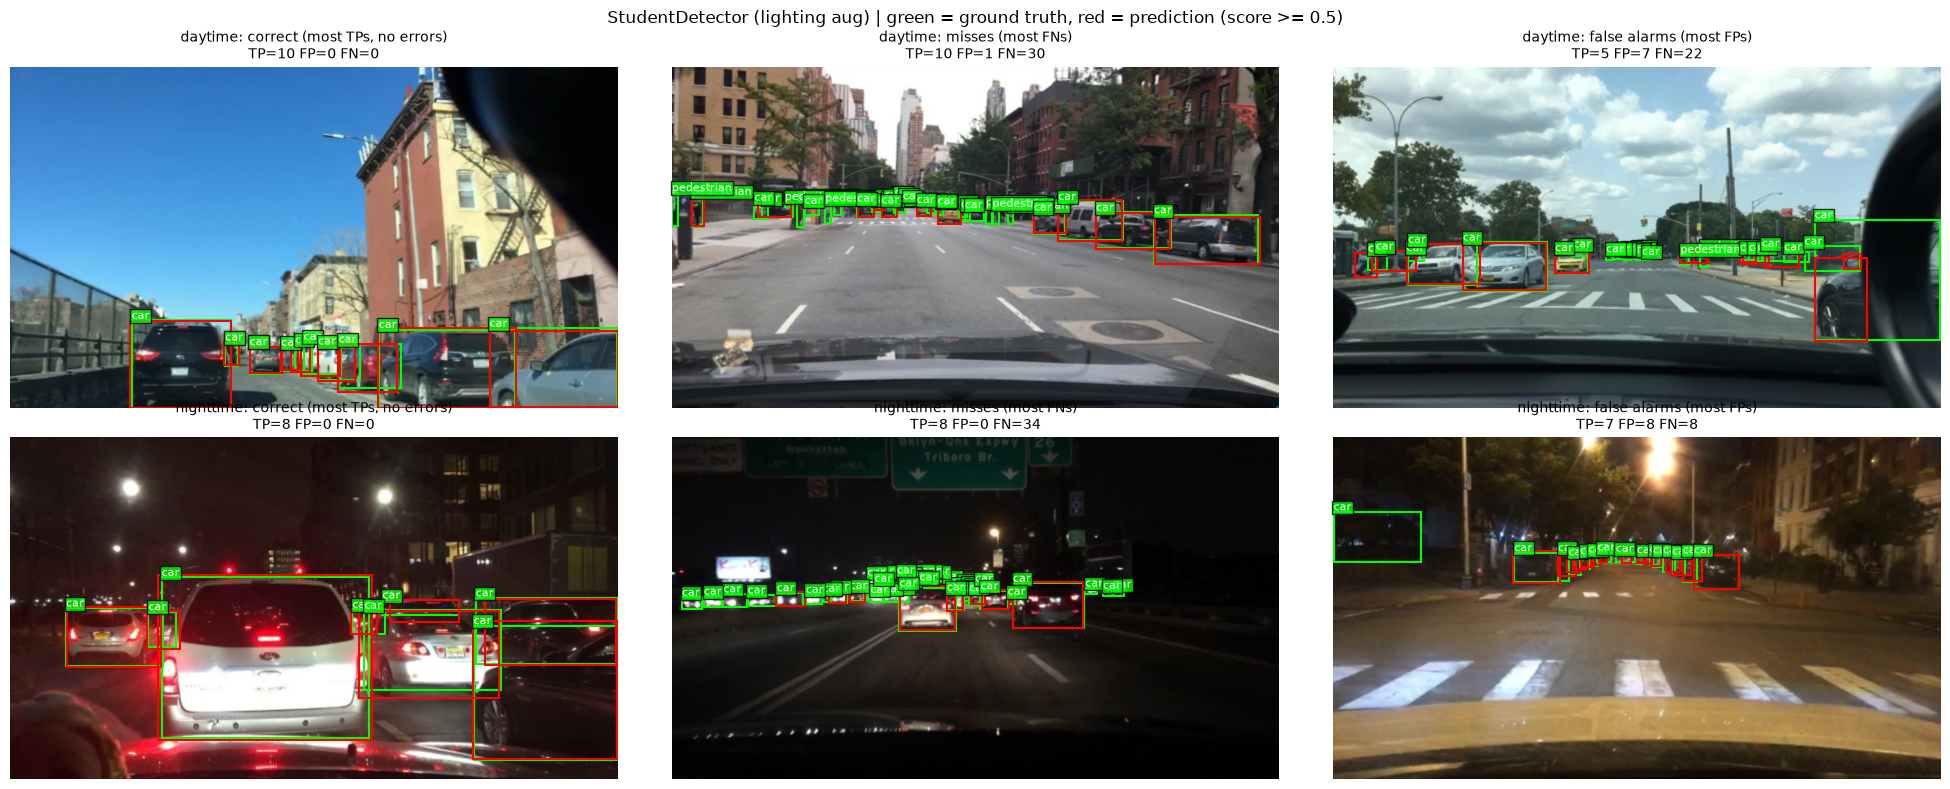

In [20]:
# Evaluate the improved detector with the ORIGINAL operating threshold (not re-tuned)
improved_preds = collect_predictions(improved_detector, val_eval, DEVICE, batch_size=BATCH_SIZE)
improved_results = evaluate_splits(improved_preds, 'StudentDetector (lighting aug)')
improved_pr_table, _ = operating_point_table(improved_preds, threshold=OPERATING_THRESHOLD)

print('Box AP / AP50 / per-class AP:')
display(pd.concat([student_results, improved_results], ignore_index=True).round(2))
print(f'Precision / recall at the original operating threshold ({OPERATING_THRESHOLD}):')
display(improved_pr_table.round(4))

# Baseline vs. improved summary (full / daytime / nighttime)
def split_pr(table, split):
    return table[table['Condition / Split'].str.startswith(split) & (table['Threshold'] == OPERATING_THRESHOLD)].iloc[0]

summary_rows = []
for split in ('Full', 'Daytime', 'Nighttime'):
    for name, res, pr in (('baseline', student_results, pr_table), ('lighting aug', improved_results, improved_pr_table)):
        ap_row, pr_row = res[res['split'] == split].iloc[0], split_pr(pr, split)
        summary_rows.append({'split': split, 'model': name, 'AP': ap_row['AP'], 'AP50': ap_row['AP50'],
                             'Precision': pr_row['Precision'], 'Recall': pr_row['Recall'], 'F1': pr_row['F1 Score'],
                             'Predictions': pr_row['Predictions']})
improvement_summary = pd.DataFrame(summary_rows)
display(improvement_summary.round(3))
for split in ('Daytime', 'Nighttime'):
    b, n = (improvement_summary[(improvement_summary['split'] == split) & (improvement_summary['model'] == m)].iloc[0] for m in ('baseline', 'lighting aug'))
    print(f'{split}: AP {b["AP"]:.2f} -> {n["AP"]:.2f} ({n["AP"] - b["AP"]:+.2f}); recall {b["Recall"]:.3f} -> {n["Recall"]:.3f}; precision {b["Precision"]:.3f} -> {n["Precision"]:.3f}')

show_detection_examples(val_eval, improved_preds, OPERATING_THRESHOLD, 'StudentDetector (lighting aug)')

# Tip: Free GPU cache when done
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

**Question:** Did nighttime performance improve? Did daytime performance decline? Support your answer with the AP and PR metrics.

**Your Answer:** Nighttime improved modestly: AP rose from 22.55 to 23.02 (+0.47) and AP50 from 45.88 to 46.72 (+0.84). Daytime did not decline; it also rose, from 25.58 to 26.28 (+0.70). At the 0.5 threshold, night precision went from 0.806 to 0.809 and recall stayed at 0.558, and day precision/recall were essentially unchanged (0.864 to 0.863, 0.554 to 0.555). The day-night gap stayed about the same (3.04 to 3.27 points). The gains are small and come from a single seed, so I can only say they are consistent with the hypothesis: the augmentation acted as general regularization rather than closing the night gap. Larger improvements would probably need night-specific data or sampling, or a stronger model.

---
## Part 2: BDD100k Instance Segmentation (5%)

### 2.1 Mask Dataset & Ground Truth Examples
For instance segmentation, we use the canonical 10k dataset subset which includes instance bitmasks. Load the segmentation training and validation datasets, and show two examples with ground-truth masks.

segmentation train images=2,682; val images=454 (day=377, night=77)


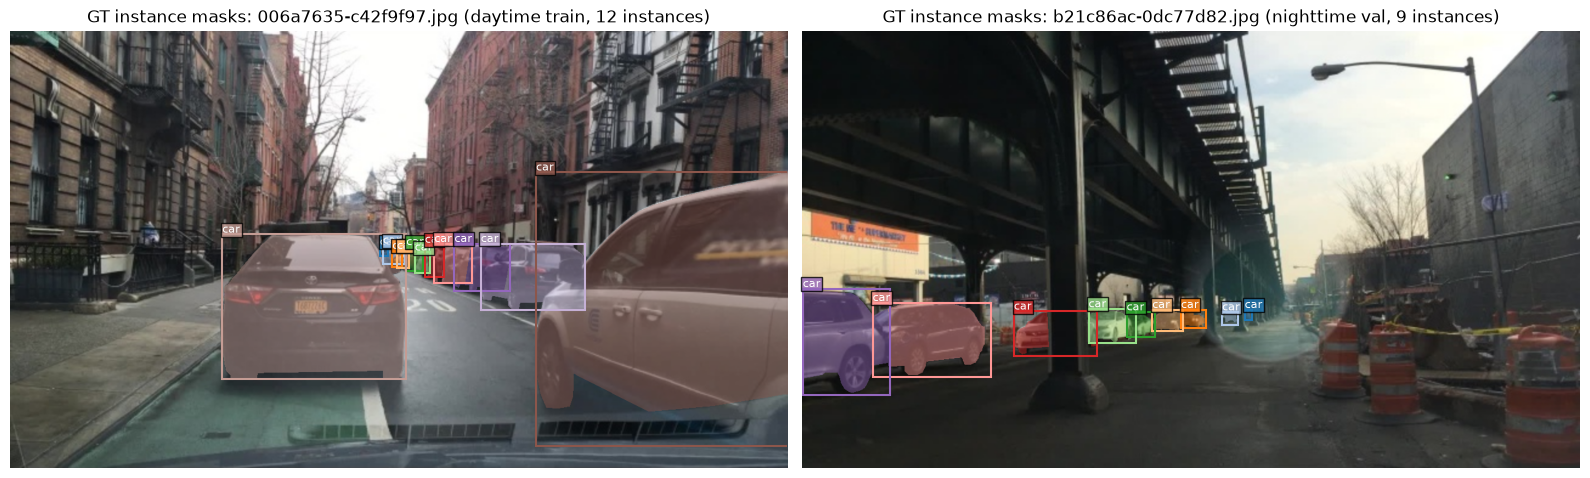

In [ ]:
# Clear Part 1 image cache and loaders to free ~3 GB RAM for Part 2
_IMAGE_BYTE_CACHE.clear()
for _k in ["train_loader", "curve_val_loader", "train_improved_loader", "student_preds", "improved_preds", "yolo_preds"]:
    if _k in globals():
        del globals()[_k]
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Paths for Part 2 Instance Segmentation (10k dataset with instance bitmasks)
SEG_TRAIN_JSON = DATA_ROOT / 'labels/ins_seg/ins_seg_train.json'
SEG_VAL_JSON = DATA_ROOT / 'labels/ins_seg/ins_seg_val.json'
SEG_TRAIN_IMAGES = DATA_ROOT / 'images/10k/train'
SEG_VAL_IMAGES = DATA_ROOT / 'images/10k/val'
MASK_TRAIN = DATA_ROOT / 'labels/ins_seg/bitmasks/train'
MASK_VAL = DATA_ROOT / 'labels/ins_seg/bitmasks/val'

seg_train_full = BDD100KDataset(SEG_TRAIN_JSON, SEG_TRAIN_IMAGES, mask_root=MASK_TRAIN)
seg_val_full = BDD100KDataset(SEG_VAL_JSON, SEG_VAL_IMAGES, mask_root=MASK_VAL)

# Reuse FAST_MODE parameters defined in Part 1 (FAST_TRAIN_IMAGES, FAST_EVAL_IMAGES, SEED)
if FAST_MODE:
    seg_train = sample_view(seg_train_full, FAST_TRAIN_IMAGES, seed=SEED)
    seg_val_eval = sample_view(seg_val_full, FAST_EVAL_IMAGES, seed=SEED + 2)
    seg_day_eval = seg_val_eval.view(timeofday="daytime")
    seg_night_eval = seg_val_eval.view(timeofday="nighttime")
else:
    seg_train = seg_train_full
    seg_val_eval = seg_val_full
    seg_day_eval = seg_val_full.view(timeofday="daytime")
    seg_night_eval = seg_val_full.view(timeofday="nighttime")

print(f"segmentation train images={len(seg_train):,}; val images={len(seg_val_eval):,} "
      f"(day={len(seg_day_eval):,}, night={len(seg_night_eval):,})")

# Two ground-truth examples: one daytime training image and one nighttime validation image
def first_with_instances(dataset, min_instances=6):
    for idx in dataset.active_indices:
        path = dataset._image_path(idx)
        if len(_boxes_and_labels(dataset.records[idx])[1]) >= min_instances:
            return idx, path
    return dataset.active_indices[0], dataset._image_path(dataset.active_indices[0])

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for ax, (ds, tod) in zip(axes, ((seg_train_full.view(timeofday="daytime"), "daytime train"),
                                (seg_val_full.view(timeofday="nighttime"), "nighttime val"))):
    idx, path = first_with_instances(ds)
    masks, mask_labels = _mask_instances(ds._mask_path(idx, path))
    boxes, _ = _boxes_and_labels(ds.records[idx])
    visualize_detections_and_masks(
        image=load_full_res_image(path),
        boxes=torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4),
        labels=torch.tensor(_boxes_and_labels(ds.records[idx])[1]),
        masks=masks,
        distinct_instance_colors=True,
        ax=ax,
    )
    ax.set_title(f"GT instance masks: {path.name} ({tod}, {len(masks)} instances)")
    ax.axis("off")
plt.tight_layout()
plt.show()


### 2.2 Implement Mask Model
Train a separate, compact mask model (any architecture discussed in class) that predicts a binary mask from an object crop. Use `build_instance_crops` from the utility functions.

In [ ]:
def mask_conv_block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.SiLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.SiLU(inplace=True),
    )

class StudentMaskNet(nn.Module):
    """Small U-Net: 128x128 normalized RGB object crop -> 128x128 foreground logits for the object in the crop."""
    def __init__(self, base=32):
        super().__init__()
        c1, c2, c3, c4 = base, base * 2, base * 4, base * 8
        self.enc1 = mask_conv_block(3, c1)       # 128x128
        self.enc2 = mask_conv_block(c1, c2)      # 64x64
        self.enc3 = mask_conv_block(c2, c3)      # 32x32
        self.enc4 = mask_conv_block(c3, c4)      # 16x16
        self.bottleneck = mask_conv_block(c4, c4)  # 8x8 (global context for the whole object)
        self.dec4 = mask_conv_block(c4 + c4, c3)
        self.dec3 = mask_conv_block(c3 + c3, c2)
        self.dec2 = mask_conv_block(c2 + c2, c1)
        self.dec1 = mask_conv_block(c1 + c1, c1)
        self.head = nn.Conv2d(c1, 1, 1)
        self.pool = nn.MaxPool2d(2)

    @staticmethod
    def _up(x, ref):
        return F.interpolate(x, size=ref.shape[-2:], mode="bilinear", align_corners=False)

    def forward(self, crops):
        e1 = self.enc1(crops)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))
        d4 = self.dec4(torch.cat([self._up(b, e4), e4], 1))
        d3 = self.dec3(torch.cat([self._up(d4, e3), e3], 1))
        d2 = self.dec2(torch.cat([self._up(d3, e2), e2], 1))
        d1 = self.dec1(torch.cat([self._up(d2, e1), e1], 1))
        return self.head(d1)

print(f"StudentMaskNet parameters: {sum(p.numel() for p in StudentMaskNet().parameters()) / 1e6:.2f}M")


StudentMaskNet parameters: 3.35M


### 2.3 Train Mask Model
Train your mask model. Plot the training loss across epochs.

Pre-extracting instance crops for 2682 training images...


Extracting Crops: 100%|██████████| 42/42 [00:33<00:00,  1.27it/s]


Extracted 58,343 crops (2734.8 MB crops, 911.6 MB masks).
Training StudentMaskNet for 30 epochs on 58,343 crops...


Epoch  1/30: loss (BCE + Dice) = 0.8009 (62s)


Epoch  2/30: loss (BCE + Dice) = 0.7185 (52s)


Epoch  3/30: loss (BCE + Dice) = 0.6969 (53s)


... (23 outputs left out)

Epoch 27/30: loss (BCE + Dice) = 0.2911 (51s)


Epoch 28/30: loss (BCE + Dice) = 0.2875 (49s)


Epoch 29/30: loss (BCE + Dice) = 0.2841 (49s)


Epoch 30/30: loss (BCE + Dice) = 0.2834 (54s)
Saved results/mask_net.pt (12.8 MB)


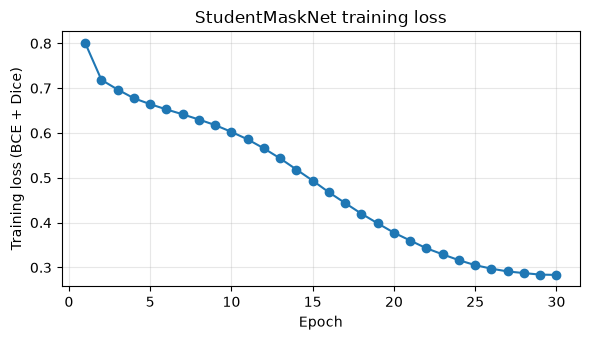

In [ ]:
# Free Part 1 DataLoaders to maximize available RAM
if "train_loader" in globals():
    del train_loader
if "curve_val_loader" in globals():
    del curve_val_loader
gc.collect()

# Step 1: Pre-extract crops once into compact uint8/bool tensors.
# Besides the exact ground-truth box, each instance is also cropped with a randomly jittered box. At inference the
# crops come from the detector's imperfect boxes, so this teaches the mask net to cope with loose or shifted boxes.
def jitter_boxes(boxes, generator, frac=0.10):
    wh = (boxes[:, 2:] - boxes[:, :2]).repeat(1, 2)
    noise = (torch.rand(boxes.shape, generator=generator) * 2 - 1) * frac * wh
    out = boxes + noise
    out[:, 2:] = torch.maximum(out[:, 2:], out[:, :2] + 2)
    return out

extract_loader = DataLoader(
    seg_train, batch_size=64, shuffle=False,
    num_workers=min(4, WORKERS), collate_fn=collate_batch
)

jitter_gen = torch.Generator().manual_seed(SEED)
all_crops, all_masks = [], []
print(f"Pre-extracting instance crops for {len(seg_train)} training images...")
for images, targets in tqdm(extract_loader, desc="Extracting Crops"):
    for img, target in zip(images, targets):
        for jitter in (False, True):
            tg = dict(target)
            if jitter:
                tg["boxes"] = jitter_boxes(target["boxes"], jitter_gen)
            crop_dict = build_instance_crops(img, tg, crop_size=128)
            if crop_dict["crops"].shape[0] > 0:
                # Store as uint8 and bool to reduce RAM by 75%
                c_u8 = ((crop_dict["crops"] * STD + MEAN).clamp(0, 1) * 255.0).round().to(torch.uint8)
                all_crops.append(c_u8)
                all_masks.append((crop_dict["masks"] > 0.5).to(torch.bool))

train_crops = torch.cat(all_crops, dim=0)
train_masks = torch.cat(all_masks, dim=0)
del all_crops, all_masks, extract_loader
gc.collect()

print(f"Extracted {train_crops.shape[0]:,} crops ({train_crops.nbytes / 1024 / 1024:.1f} MB crops, {train_masks.nbytes / 1024 / 1024:.1f} MB masks).")

# Step 2: High-speed GPU training from contiguous in-memory TensorDataset
from torch.utils.data import TensorDataset
crop_dataset = TensorDataset(train_crops, train_masks)
crop_loader = DataLoader(crop_dataset, batch_size=64, shuffle=True, pin_memory=(DEVICE.type == "cuda"))

set_seeds(SEED)
mask_net = StudentMaskNet().to(DEVICE)
mask_epochs = EPOCHS if FAST_MODE else 2 * EPOCHS

mask_optimizer = torch.optim.AdamW(mask_net.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
mask_scheduler = torch.optim.lr_scheduler.OneCycleLR(
    mask_optimizer, max_lr=LEARNING_RATE, total_steps=mask_epochs * len(crop_loader), pct_start=0.1)
mask_criterion = nn.BCEWithLogitsLoss()

def dice_loss(logits, targets, eps=1.0):
    probs = torch.sigmoid(logits).flatten(1)
    targets = targets.flatten(1)
    inter = (probs * targets).sum(1)
    return (1 - (2 * inter + eps) / (probs.sum(1) + targets.sum(1) + eps)).mean()

# Pre-allocate normalization tensors directly on DEVICE to avoid device mismatch errors
mean = torch.tensor([0.485, 0.456, 0.406], device=DEVICE, dtype=torch.float32).view(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225], device=DEVICE, dtype=torch.float32).view(1, 3, 1, 1)

mask_history = []
print(f"Training StudentMaskNet for {mask_epochs} epochs on {len(crop_dataset):,} crops...")

for epoch in range(1, mask_epochs + 1):
    mask_net.train()
    total_loss = 0.0
    t0 = time.time()

    pbar = tqdm(crop_loader, desc=f"Epoch {epoch:02d}/{mask_epochs:02d} [MaskNet]", leave=False)
    for c_u8, m_bool in pbar:
        # Stream to GPU and normalize on-the-fly
        crops = c_u8.to(DEVICE, non_blocking=True).to(torch.float32).div_(255.0).sub_(mean).div_(std)
        gt_masks = m_bool.to(DEVICE, non_blocking=True).to(torch.float32)

        # Random horizontal flip of each crop together with its mask
        flip = torch.rand(crops.shape[0], device=DEVICE) < 0.5
        crops = torch.where(flip.view(-1, 1, 1, 1), crops.flip(-1), crops)
        gt_masks = torch.where(flip.view(-1, 1, 1, 1), gt_masks.flip(-1), gt_masks)

        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=(DEVICE.type == "cuda")):
            logits = mask_net(crops)
        logits = logits.float()
        loss = mask_criterion(logits, gt_masks) + dice_loss(logits, gt_masks)

        mask_optimizer.zero_grad(set_to_none=True)
        loss.backward()
        mask_optimizer.step()
        mask_scheduler.step()

        total_loss += loss.item() * crops.shape[0]
        pbar.set_postfix(loss=f"{loss.item():.3f}")

    avg_loss = total_loss / len(crop_dataset)
    mask_history.append(avg_loss)
    print(f"Epoch {epoch:2d}/{mask_epochs:2d}: loss (BCE + Dice) = {avg_loss:.4f} ({time.time() - t0:.0f}s)")

torch.save(mask_net.state_dict(), OUTPUT_DIR / 'mask_net.pt')
print(f"Saved {OUTPUT_DIR / 'mask_net.pt'} ({(OUTPUT_DIR / 'mask_net.pt').stat().st_size / 1024 / 1024:.1f} MB)")

# Clean up in-memory dataset and training objects to restore RAM
del train_crops, train_masks, crop_dataset, crop_loader
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

plt.figure(figsize=(6, 3.5))
plt.plot(range(1, len(mask_history) + 1), mask_history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training loss (BCE + Dice)")
plt.title("StudentMaskNet training loss")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Question:** Briefly discuss the model's training behaviour.

**Your Answer:** The loss (BCE + Dice) falls steadily from 0.80 in epoch 1 to 0.28 in epoch 30, with no spikes or divergence, and it flattens over the last few epochs as the one-cycle learning rate decays to zero. 58,343 crops were used (2,682 images; each object is cropped once with its exact box and once with a randomly jittered box, to match the imperfect boxes the detector produces at inference), at about 53 s per epoch. Only the training loss is tracked here, and 58k crops from 2.7k images could be overfit, so the held-out check matters: with ground-truth boxes the mask network scores 19.5 mask AP / 54.8 AP50 on the unseen validation images (table in 2.6), so it generalizes well, and the final pipeline clears the targets of 7.5 AP and 16 AP50 (16.1 / 38.6).

### 2.4 Segmentation Inference
At inference, use your detector's predicted boxes to extract crops, predict one mask per object, and place the masks back into the original image using `paste_crop_masks`.

In [ ]:
def segment_boxes(mask_net, image, boxes, crop_size=128, mask_threshold=0.50):
    """Crops each box from a normalized (3, H, W) image, predicts one mask per crop and pastes it back (H, W)."""
    H, W = image.shape[-2:]
    if len(boxes) == 0:
        return torch.zeros((0, H, W), dtype=torch.bool, device=image.device)
    crops = []
    for box in boxes:
        x1, y1, x2, y2 = box.round().long().tolist()
        # Same clamping as paste_crop_masks so the crop and the paste target are identical
        x1, x2 = max(0, min(x1, W - 1)), max(1, min(x2, W))
        y1, y2 = max(0, min(y1, H - 1)), max(1, min(y2, H))
        if x2 <= x1 or y2 <= y1:
            crops.append(torch.zeros((3, crop_size, crop_size), device=image.device))
        else:
            crops.append(F.interpolate(image[None, :, y1:y2, x1:x2], size=(crop_size, crop_size),
                                       mode="bilinear", align_corners=False)[0])
    with torch.autocast("cuda", dtype=torch.bfloat16, enabled=image.is_cuda):
        logits = mask_net(torch.stack(crops))
    return paste_crop_masks(torch.sigmoid(logits.float()), boxes, (H, W), threshold=mask_threshold)

@torch.inference_mode()
def predict_segmentation(detector, mask_net, images, score_threshold=0.25):
    # Detector boxes -> crops -> mask net -> masks pasted back on the 640x384 letterboxed canvas.
    detector.eval()
    mask_net.eval()
    results = []
    for image, det in zip(images, detector.predict(images)):
        keep = det["scores"] >= score_threshold
        boxes, labels, scores = det["boxes"][keep], det["labels"][keep], det["scores"][keep]
        results.append({"boxes": boxes, "labels": labels, "scores": scores,
                        "masks": segment_boxes(mask_net, image, boxes)})
    return results

class StudentSegPipeline(nn.Module):
    """Wrapper making the combined detection + segmentation model compatible with collect_predictions."""
    def __init__(self, detector, mask_net, score_threshold=0.25):
        super().__init__()
        self.detector = detector
        self.mask_net = mask_net
        self.score_threshold = score_threshold

    def predict(self, images):
        return predict_segmentation(self.detector, self.mask_net, images, score_threshold=self.score_threshold)


### 2.5 YOLO26-seg Setup
Load the pretrained YOLO26-seg model. Document your choice of size.

In [ ]:
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# YOLO26m-seg: same size as the detection model used in Part 1 (accurate but still fast on a single GPU)
YOLO_SEG_WEIGHTS = 'yolo26m-seg.pt'
yolo_seg_model = YOLO(YOLO_SEG_WEIGHTS)
print(f"{YOLO_SEG_WEIGHTS}: {sum(p.numel() for p in yolo_seg_model.model.parameters()) / 1e6:.1f}M parameters")


yolo26m-seg.pt: 27.1M parameters


**Question:** Which YOLO26-seg model size did you select?

**Your Answer:** YOLO26m-seg (`yolo26m-seg.pt`, 27.1M parameters), the medium size. I used the same size as the Part 1 detector (YOLO26m) so the detection and segmentation comparisons are consistent. It is accurate enough to be a meaningful pretrained reference but still evaluates the validation set in under a minute on one GPU; the larger sizes cost much more for a modest gain on the three classes used here.

### 2.6 Evaluate Mask AP (Daytime & Nighttime)
Evaluate your trained segmentation pipeline (detector + mask model) on daytime and nighttime subsets using `evaluate_coco` with `iou_type='segm'`. Remember to map COCO classes to our BDD classes as before.

In [ ]:
seg_day_ids = set(int(i) for i in seg_day_eval.active_indices)
seg_night_ids = set(int(i) for i in seg_night_eval.active_indices)

def evaluate_mask_splits(preds, name):
    # Mask AP / AP50 and per-class mask AP on the full, daytime and nighttime validation sets
    rows = []
    for split, ds, ids in (('Full', seg_val_eval, None), ('Daytime', seg_day_eval, seg_day_ids), ('Nighttime', seg_night_eval, seg_night_ids)):
        subset = preds if ids is None else [p for p in preds if int(p['image_id']) in ids]
        with contextlib.redirect_stdout(io.StringIO()):
            res = evaluate_coco(ds, subset, iou_type='segm')
        row = {'model': name, 'split': split, 'images': len(ds), 'mask AP': 100 * res['AP'], 'mask AP50': 100 * res['AP50']}
        row.update({f'AP {c}': 100 * res['per_class'][c]['AP'] for c in CLASS_NAMES})
        rows.append(row)
    return pd.DataFrame(rows)

# Student pipeline: improved detector (Part 1) + StudentMaskNet. A low score threshold keeps recall high for AP.
mask_net.eval()
seg_pipeline = StudentSegPipeline(improved_detector, mask_net, score_threshold=0.05)
student_seg_preds = collect_predictions(seg_pipeline, seg_val_eval, DEVICE, batch_size=16, workers=0, desc='Student segmentation')
student_seg_results = evaluate_mask_splits(student_seg_preds, 'Student pipeline (detector + MaskNet)')

# Oracle: the same mask net applied to perfect ground-truth boxes. It isolates the mask model's own quality
# from the detector's errors (used for the error attribution in 2.9).
def masks_to_full_res_rles(letter_masks, target):
    pad_x, pad_y = int(round(target["pad"][0])), int(round(target["pad"][1]))
    scale = float(target["scale"])
    sh, sw = target["original_size"]
    ch, cw = max(1, min(IMAGE_HEIGHT - pad_y, round(sh * scale))), max(1, min(IMAGE_WIDTH - pad_x, round(sw * scale)))
    rles = []
    for m in letter_masks.float().cpu():
        m_up = (F.interpolate(m[None, None, pad_y:pad_y + ch, pad_x:pad_x + cw], size=(sh, sw), mode="bilinear", align_corners=False)[0, 0] >= 0.5).numpy().astype(np.uint8)
        rle = mask_utils.encode(np.asfortranarray(m_up))
        rle["counts"] = rle["counts"].decode("ascii")
        rles.append(rle)
    return rles

oracle_preds = []
oracle_loader = DataLoader(seg_val_eval, batch_size=16, shuffle=False, num_workers=0, collate_fn=collate_batch)
with torch.inference_mode():
    for images, targets in tqdm(oracle_loader, desc='Oracle boxes', leave=False):
        images = images.to(DEVICE)
        for image, target in zip(images, targets):
            boxes = target["boxes"].to(DEVICE)
            oracle_preds.append({
                "image_id": target["image_id"], "boxes": target["orig_boxes"], "labels": target["labels"],
                "scores": torch.ones(len(boxes)), "timeofday": target["timeofday"], "file_name": target["file_name"],
                "masks": masks_to_full_res_rles(segment_boxes(mask_net, image, boxes), target),
            })
oracle_results = evaluate_mask_splits(oracle_preds, 'MaskNet on ground-truth boxes (oracle)')
del oracle_loader

mask_ap_table = pd.concat([student_seg_results, oracle_results], ignore_index=True)
display(mask_ap_table.round(2))
for name, res in (('Student pipeline', student_seg_results), ('MaskNet + GT boxes', oracle_results)):
    r = res.set_index('split')
    print(f"{name}: day mask AP={r.loc['Daytime', 'mask AP']:.2f}, night mask AP={r.loc['Nighttime', 'mask AP']:.2f}, "
          f"gap (day - night)={r.loc['Daytime', 'mask AP'] - r.loc['Nighttime', 'mask AP']:.2f} AP points")

# Tip: Free GPU cache when done
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


,model,split,images,mask AP,mask AP50,AP car,AP pedestrian,AP bicycle
0,Student pipeline (detector + MaskNet),Full,454,16.14,38.55,32.58,12.35,3.48
1,Student pipeline (detector + MaskNet),Daytime,377,16.28,38.80,32.90,12.37,3.58
2,Student pipeline (detector + MaskNet),Nighttime,77,14.65,33.04,30.86,13.07,0.02
3,MaskNet on ground-truth boxes (oracle),Full,454,19.53,54.75,32.23,17.60,8.77
4,MaskNet on ground-truth boxes (oracle),Daytime,377,19.43,54.24,32.18,17.25,8.85
5,MaskNet on ground-truth boxes (oracle),Nighttime,77,21.80,64.74,33.92,21.38,10.10


Student pipeline: day mask AP=16.28, night mask AP=14.65, gap (day - night)=1.63 AP points
MaskNet + GT boxes: day mask AP=19.43, night mask AP=21.80, gap (day - night)=-2.37 AP points


### 2.7 Compare with Pretrained Baseline
Evaluate the YOLO26-seg model on the full validation set. Note that YOLO26 segmentation runs end to end (detection and segmentation).

In [ ]:
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# COCO ids person=0, bicycle=1, car=2 -> BDD ids pedestrian=1, bicycle=2, car=0
COCO_TO_BDD = torch.tensor([1, 2, 0])

class YoloSegPredictor:
    """Adapts YOLO26-seg to the predict(images) interface used by collect_predictions.
    Images are already letterboxed to 640x384, so boxes and masks come back on that same canvas."""
    def __init__(self, yolo):
        self.yolo = yolo

    def eval(self):
        return self

    def predict(self, images):
        x = (images * STD.to(images.device) + MEAN.to(images.device)).clamp(0, 1).contiguous()
        H, W = x.shape[-2:]
        outputs = []
        for res in self.yolo.predict(x, imgsz=640, conf=0.01, iou=0.7, max_det=100, classes=[0, 1, 2], verbose=False, device=DEVICE):
            if res.masks is None or len(res.boxes) == 0:
                outputs.append({'boxes': torch.zeros((0, 4)), 'labels': torch.zeros((0,), dtype=torch.long),
                                'scores': torch.zeros((0,)), 'masks': torch.zeros((0, H, W))})
                continue
            masks = res.masks.data.float()
            if masks.shape[-2:] != (H, W):
                masks = F.interpolate(masks[None], size=(H, W), mode='bilinear', align_corners=False)[0]
            outputs.append({'boxes': res.boxes.xyxy.float(), 'labels': COCO_TO_BDD[res.boxes.cls.cpu().long()].to(x.device),
                            'scores': res.boxes.conf.float(), 'masks': masks})
        return outputs

yolo_seg_preds = collect_predictions(YoloSegPredictor(yolo_seg_model), seg_val_eval, DEVICE, batch_size=16, workers=0, desc='YOLO26-seg')
yolo_seg_results = evaluate_mask_splits(yolo_seg_preds, f'YOLO26-seg ({YOLO_SEG_WEIGHTS})')

seg_comparison_table = pd.concat([student_seg_results, yolo_seg_results], ignore_index=True)
display(seg_comparison_table.round(2))
for name, res in (('Student pipeline', student_seg_results), ('YOLO26-seg', yolo_seg_results)):
    r = res.set_index('split')
    print(f"{name}: full mask AP={r.loc['Full', 'mask AP']:.2f}, AP50={r.loc['Full', 'mask AP50']:.2f}; "
          f"day={r.loc['Daytime', 'mask AP']:.2f}, night={r.loc['Nighttime', 'mask AP']:.2f}, gap={r.loc['Daytime', 'mask AP'] - r.loc['Nighttime', 'mask AP']:.2f}")

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


,model,split,images,mask AP,mask AP50,AP car,AP pedestrian,AP bicycle
0,Student pipeline (detector + MaskNet),Full,454,16.14,38.55,32.58,12.35,3.48
1,Student pipeline (detector + MaskNet),Daytime,377,16.28,38.80,32.90,12.37,3.58
2,Student pipeline (detector + MaskNet),Nighttime,77,14.65,33.04,30.86,13.07,0.02
3,YOLO26-seg (yolo26m-seg.pt),Full,454,18.79,45.78,26.82,18.96,10.58
4,YOLO26-seg (yolo26m-seg.pt),Daytime,377,18.82,46.29,26.67,18.65,11.15
5,YOLO26-seg (yolo26m-seg.pt),Nighttime,77,16.76,36.47,28.72,21.55,0.00


Student pipeline: full mask AP=16.14, AP50=38.55; day=16.28, night=14.65, gap=1.63
YOLO26-seg: full mask AP=18.79, AP50=45.78; day=18.82, night=16.76, gap=2.07


### 2.8 Visualize Example Segmentations
Display images comparing correct and incorrect segmentations. Show two examples that distinguish a missed detection (where the box completely failed) from an inaccurate mask (where the box was okay but the mask failed).

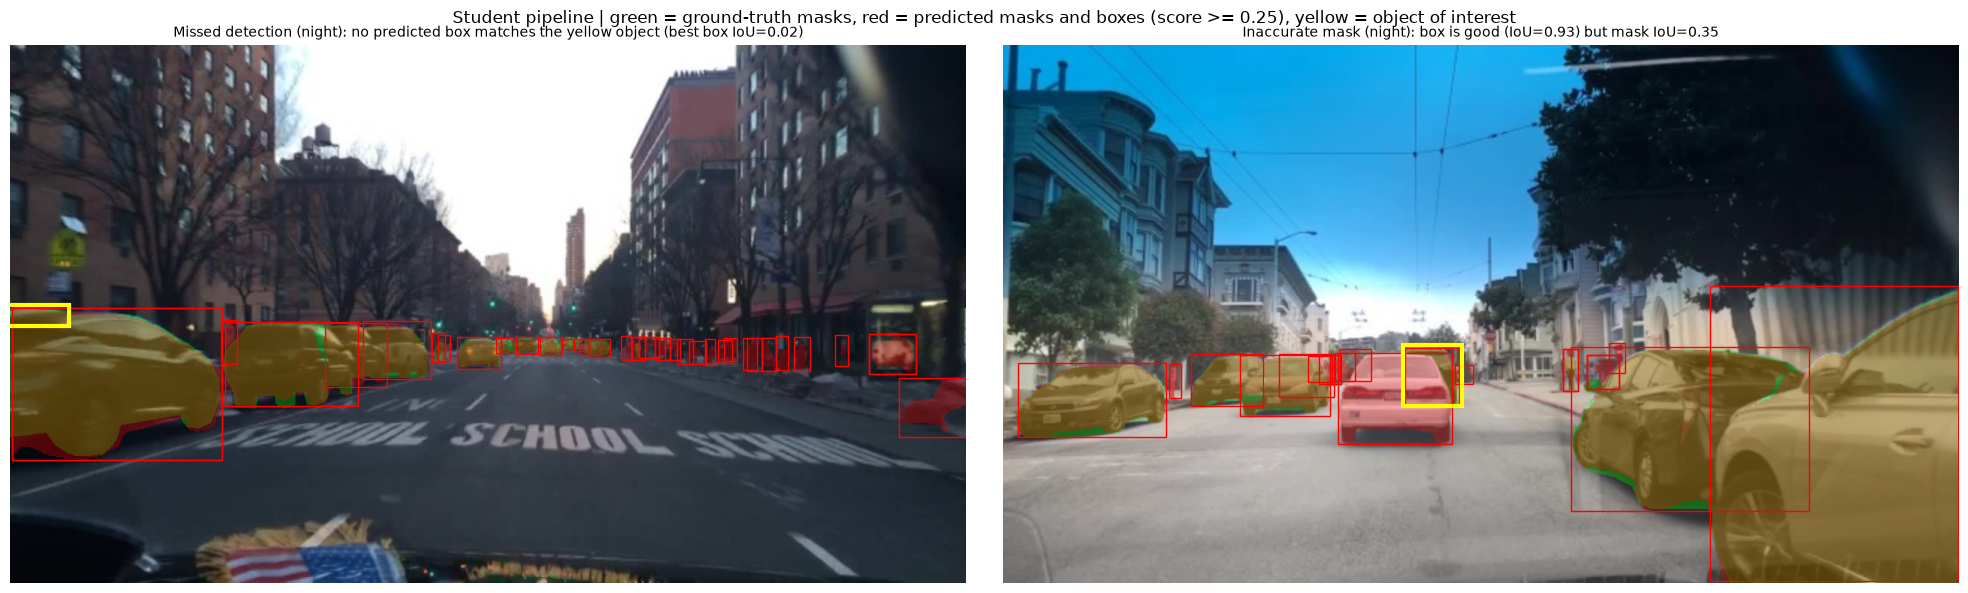

Large GT instances (area >= 1500 px) at score threshold 0.25:
  night: n=283  box missed (best box IoU<0.5)=5 (1.8%)  box ok but mask IoU<0.5=12 (4.2%)  mask IoU>=0.5=266 (94.0%)
  day: n=1744  box missed (best box IoU<0.5)=35 (2.0%)  box ok but mask IoU<0.5=70 (4.0%)  mask IoU>=0.5=1639 (94.0%)


In [ ]:
def instance_rles(dataset, idx):
    # Ground-truth instance masks at the original 1280x720 resolution, as COCO RLEs with their tight boxes
    masks, labels = _mask_instances(dataset._mask_path(idx, dataset._image_path(idx)))
    rles = [mask_utils.encode(np.asfortranarray(m.astype(np.uint8))) for m in masks]
    return rles, labels

def analyze_image(dataset, idx, pred, score_threshold=0.25, min_area=1500):
    # For every sizeable GT instance: best box IoU over predictions, and the mask IoU of that best-box prediction
    gt_rles, gt_labels = instance_rles(dataset, idx)
    keep = [i for i, s in enumerate(pred['scores'].tolist()) if s >= score_threshold and i < len(pred['masks'])]
    out = []
    if not gt_rles:
        return out, gt_rles, gt_labels, keep
    gt_boxes = [list(mask_utils.toBbox(r)) for r in gt_rles]
    gt_area = [float(mask_utils.area(r)) for r in gt_rles]
    if keep:
        pb = [[float(b[0]), float(b[1]), float(b[2] - b[0]), float(b[3] - b[1])] for b in pred['boxes'][keep].tolist()]
        box_iou = np.asarray(mask_utils.iou(pb, gt_boxes, [0] * len(gt_boxes)))
        mask_iou = np.asarray(mask_utils.iou([pred['masks'][i] for i in keep], gt_rles, [0] * len(gt_rles)))
    for g in range(len(gt_rles)):
        if gt_area[g] < min_area:
            continue
        if keep:
            p = int(np.argmax(box_iou[:, g]))
            out.append((g, float(box_iou[p, g]), float(mask_iou[p, g]), keep[p], gt_area[g]))
        else:
            out.append((g, 0.0, 0.0, None, gt_area[g]))
    return out, gt_rles, gt_labels, keep

def overlay_masks(ax, rles, color, alpha=0.45):
    h, w = rles[0]['size']
    canvas = np.zeros((h, w, 4), dtype=np.float32)
    for r in rles:
        canvas[mask_utils.decode(r).astype(bool)] = (*to_rgb(color), alpha)
    ax.imshow(canvas)

def draw_example(ax, dataset, idx, pred, gt_index, kind, score_threshold=0.25):
    _, gt_rles, gt_labels, keep = analyze_image(dataset, idx, pred, score_threshold)
    visualize_detections_and_masks(load_full_res_image(dataset._image_path(idx)), ax=ax)
    overlay_masks(ax, gt_rles, 'lime', alpha=0.30)
    if keep:
        overlay_masks(ax, [pred['masks'][i] for i in keep], 'red', alpha=0.30)
        for i in keep:
            x1, y1, x2, y2 = pred['boxes'][i].tolist()
            ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color='red', linewidth=1.0))
    x, y, w, h = mask_utils.toBbox(gt_rles[gt_index])
    ax.add_patch(plt.Rectangle((x - 4, y - 4), w + 8, h + 8, fill=False, color='yellow', linewidth=3))
    ax.set_title(kind, fontsize=10)
    ax.axis('off')

by_image = {int(p['image_id']): p for p in student_seg_preds}
missed_best = inaccurate_best = None  # (score, image index, gt index, box IoU, mask IoU)
night_pool = list(seg_night_eval.active_indices)
for idx in night_pool:
    rows, *_ = analyze_image(seg_val_eval, idx, by_image[idx], min_area=300)
    for g, b_iou, m_iou, _p, area in rows:
        if b_iou < 0.1:
            cand = (area, idx, g, b_iou, m_iou)  # complete misses: prefer the largest missed object
            if missed_best is None or cand[0] > missed_best[0]:
                missed_best = cand
        elif b_iou >= 0.75 and area >= 1500:
            cand = (b_iou - m_iou, idx, g, b_iou, m_iou)
            if inaccurate_best is None or cand[0] > inaccurate_best[0]:
                inaccurate_best = cand

fig, axes = plt.subplots(1, 2, figsize=(20, 6))
if missed_best is not None:
    _, idx, g, b_iou, m_iou = missed_best
    draw_example(axes[0], seg_val_eval, idx, by_image[idx], g,
                 f'Missed detection (night): no predicted box matches the yellow object (best box IoU={b_iou:.2f})')
if inaccurate_best is not None:
    _, idx, g, b_iou, m_iou = inaccurate_best
    draw_example(axes[1], seg_val_eval, idx, by_image[idx], g,
                 f'Inaccurate mask (night): box is good (IoU={b_iou:.2f}) but mask IoU={m_iou:.2f}')
fig.suptitle('Student pipeline | green = ground-truth masks, red = predicted masks and boxes (score >= 0.25), yellow = object of interest')
plt.tight_layout()
plt.show()

# Quantify error attribution on all night images: how many sizeable GT instances are missed vs have a poor mask
counts = {'night': [0, 0, 0, 0], 'day': [0, 0, 0, 0]}
for tod, ds in (('night', seg_night_eval), ('day', seg_day_eval)):
    for idx in ds.active_indices:
        rows, *_ = analyze_image(ds, idx, by_image[idx])
        for g, b_iou, m_iou, _p, area in rows:
            counts[tod][0] += 1
            if b_iou < 0.5:
                counts[tod][1] += 1
            elif m_iou < 0.5:
                counts[tod][2] += 1
            else:
                counts[tod][3] += 1
print('Large GT instances (area >= 1500 px) at score threshold 0.25:')
for tod, (n, miss, badmask, ok) in counts.items():
    print(f'  {tod}: n={n}  box missed (best box IoU<0.5)={miss} ({100 * miss / max(n, 1):.1f}%)  '
          f'box ok but mask IoU<0.5={badmask} ({100 * badmask / max(n, 1):.1f}%)  mask IoU>=0.5={ok} ({100 * ok / max(n, 1):.1f}%)')


**Question:** What is the mask AP gap between daytime and nighttime performance?

**Your Answer:** The student pipeline (improved detector + MaskNet) gets 16.28 mask AP in the daytime and 14.65 at night, a gap of 1.63 points (AP50: 38.80 vs 33.04, a gap of 5.8). YOLO26m-seg has a similar gap: 18.82 vs 16.76, i.e. 2.06 points. The gap is small, but the night subset has only 77 images (377 for day) and almost no night bicycles (night bicycle AP is about 0), so the night numbers are noisy. The pipeline reaches 16.14 mask AP / 38.55 AP50 overall, versus 18.79 / 45.78 for YOLO26m-seg, and beats the 7.5 / 16 targets.

### 2.9 Interpret Results
**Question:** Discuss the error attribution between your detector and your mask model. When segmentations fail at night, is it primarily because the detector missed the object, or because the mask model failed to generate a tight mask from a valid box crop?

**Your Answer:** The detector is the main bottleneck at night, not the mask network. (1) Feeding the mask network perfect ground-truth boxes gives 21.80 mask AP at night, higher than its 19.43 by day, whereas with the detector's boxes the pipeline falls to 14.65 at night (a drop of 7.2 points) versus 16.28 by day (a drop of 3.2). So the drop caused by the detector is more than twice as large at night, and the mask network alone shows no night weakness. (2) Among large objects (area >= 1500 px, score >= 0.25), the box is missed (best box IoU < 0.5) for only 1.8% at night and 2.0% by day, and a valid box is given a poor mask (IoU < 0.5) for 4.2% at night and 4.0% by day, so large objects are handled equally well in both conditions. The AP lost at night therefore comes mostly from small, distant or dark objects, where the detector misses or mislocalizes the object; these are also the cases where AP50 falls most (38.8 to 33.0). When the box is good but the mask fails (second example above), the usual cause is occlusion: the crop contains a neighbouring vehicle, and the mask network, which sees only the crop, segments the more visible car. Caveat: the night subset has 77 images, so these percentages are rough.

### 2.10 Segmentation Hypothesis
**Question:** State a hypothesis about one nighttime segmentation weakness and what change you might make to address it (no retraining required for this step).

**Your Answer:** Hypothesis: at night, object boundaries are low-contrast (dark cars against dark road, glare from headlights), so the mask network, which sees only a box crop, produces ragged or wrongly extended masks and confuses an occluded object with the brighter vehicle in front of it. A change that needs no retraining is to normalize the contrast of every crop before it enters the mask network (for example per-crop standardization or CLAHE on the luminance channel, and optionally averaging the mask with that of the horizontally flipped crop). A follow-up that does need retraining would be brightness and contrast augmentation of the training crops, as was done for the detector. I did not test either change here.

## Report (2%) & Submission Checklist

Remember to copy and paste appropriate images, tables, etc into the report from the notebook. Do not simply make reference to a table in the notebook - the report should be self contained.

### Report Outline & Questions to Address (1–2 Pages):
1. **AP & Operating Point Tables**: Report Full, Day, and Night Box AP and Mask AP for Student vs. YOLO, and precision/recall across thresholds.
2. **Day vs. Night Comparison**: Discuss why high-confidence precision remains high (~99%) while recall and medium/large object AP drop at night.
3. **Nighttime Failure Modes & Intervention**: Why do detectors experience drops at night, even with 40% night driving data? How did your targeted improvement (lighting augmentation / additional night images) address contrast loss, and how well did it work?
4. **Student Model vs. YOLO**: Why does the student model beat YOLO on BDD100K cars despite being smaller, and under what conditions is domain-specific training worth it?
5. **Class Imbalance & Temporal Leakage**: Discuss BDD100K class imbalance (cars vs pedestrians/cyclists) and video frame correlation.

### Expected Submission Files (.zip):
1. **Completed Notebook**: `solution.ipynb` (or your completed notebook) with all outputs and figures clearly visible.
2. **PDF Report**: 1–2 page PDF summarizing your findings, AP tables, and precision/recall operating points.
3. **`results/` Folder**: Must contain your saved model checkpoints (each under 100MB):
   * `results/baseline_detector.pt` — Section 1.5 baseline detector
   * `results/improved_detector.pt` — Section 1.11 retrained nighttime detector
   * `results/mask_net.pt` — Section 2.3 trained instance segmentation mask network
   *(Do NOT include the image dataset in your submission zip!)*

### Pre-formatted Report Tables (Copy & Paste into Report)

#### Table 1: Main AP Results Summary

| System and AP type | Full AP (%) | AP50 (%) | Day AP (%) | Night AP (%) | Day - Night Gap (pp) |
| :--- | :---: | :---: | :---: | :---: | :---: |
| Student detector — box | 24.69 | 48.40 | 25.58 | 22.55 | 3.04 |
| YOLO26 detector (medium) — box | 28.53 | 52.70 | 30.74 | 23.00 | 7.74 |
| Student pipeline — mask | 16.14 | 38.55 | 16.28 | 14.65 | 1.63 |
| YOLO26-seg (medium) — mask | 18.79 | 45.78 | 18.82 | 16.76 | 2.06 |
| Improved detector — box | 25.37 | 49.28 | 26.28 | 23.02 | 3.26 |

---

#### Table 2: Precision & Recall Operating Point Table (Section 1.8)

| Condition / Split | Threshold | Precision | Recall | F1 Score | Predictions |
| :--- | :---: | :---: | :---: | :---: | :---: |
| Full Validation | 0.25 | 0.3022 | 0.7370 | 0.4287 | 286320 |
| **Full Validation (Chosen)** | **0.50** | 0.8437 | 0.5551 | 0.6696 | 77253 |
| Full Validation | 0.75 | 0.9880 | 0.2425 | 0.3895 | 28826 |
| Daytime (Chosen) | 0.50 | 0.8640 | 0.5536 | 0.6748 | 43840 |
| Nighttime (Chosen) | 0.50 | 0.8062 | 0.5579 | 0.6594 | 27047 |
